<a href="https://colab.research.google.com/github/ATVermillion/deep-regime-detection-core-satellite-taa/blob/main/Capstone_Project_Develop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regime-Adaptive Core-Satellite Allocation Using Deep Regime Detection
MScFE 690 Capstone Project | Group 17837 | Track 8.1: Machine Learning (Deep) Market Timing Strategies

## 1 Configuration

In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
#  Universe definition 
CORE_TICKER = "SPY"

# Satellite sleeve held in a predicted TRENDING regime (equal-weighted)
AGGRESSIVE_TICKERS = [
    "NVDA", "AMD", "AVGO",      # semiconductors
    "TSLA", "AMZN",             # consumer discretionary
    "META", "NFLX",             # communication services
    "CRM",                      # software
    "GS", "CAT",                # financials / industrials (cyclical)
]

# Satellite sleeve held in a predicted STRESSED regime (equal-weighted)
DEFENSIVE_TICKERS = ["TLT", "GLD"]   # long Treasuries, gold

SATELLITE_TICKERS = AGGRESSIVE_TICKERS + DEFENSIVE_TICKERS
TICKERS = [CORE_TICKER] + SATELLITE_TICKERS

#  Portfolio structure (fixed wrapper) 
CORE_WEIGHT = 0.50           # SPY
SATELLITE_WEIGHT = 0.50      # regime signal chooses aggressive vs defensive sleeve
REBALANCE_BAND = 0.10        # rebalance if core/satellite weight drifts > 10 pts

#  Sample period 
START_DATE = "2015-01-01"
END_DATE = "2026-10-01"

## 2 Read Data

**Data snapshot.** All market and macro data are downloaded once and saved to `data/snapshot/`.
Every later run reads these files, so results are reproducible (Yahoo revises adjusted prices over time)
and the notebook runs without internet or a FRED key. Set `REFRESH_SNAPSHOT = True` to re-download.

In [ ]:
#  Data snapshot: download once (needs internet + FRED key), then every run reads the same files 
import requests

SNAP_DIR = "data/snapshot"
REFRESH_SNAPSHOT = False                          # True = re-download and overwrite the snapshot

ETF_TICKERS = ["XLK", "XLY", "XLF", "XLI", "XLE", "XLB", "XLV", "XLP", "XLU"]   # sector-ETF robustness pool
EXTRA_TICKERS = ["SHY", "BIL", "IEF"]             # short/intermediate Treasuries (defensive-sleeve variants)
FRED_SERIES = {"y10": "DGS10", "spread_10y2y": "T10Y2Y", "fedfunds": "DFF",
               "tbill_3m": "DGS3MO"}             # tbill_3m: risk-free rate for excess-return Sharpe ratios
SNAP_FILES = {k: f"{SNAP_DIR}/{k}.csv" for k in ["close", "volume", "macro"]}

def fred(series_id, api_key, start=START_DATE, end=END_DATE):
    """Download one FRED series as a float Series indexed by date."""
    params = {"series_id": series_id, "api_key": api_key, "file_type": "json",
              "observation_start": start, "observation_end": end}
    r = requests.get("https://api.stlouisfed.org/fred/series/observations", params=params, timeout=30)
    if r.status_code != 200:
        # report the status only: the full URL would expose the API key
        raise RuntimeError(f"FRED request for {series_id} failed (HTTP {r.status_code})")
    obs = pd.DataFrame(r.json()["observations"])
    values = pd.to_numeric(obs["value"], errors="coerce")          # "." marks missing days
    return pd.Series(values.values, index=pd.to_datetime(obs["date"]), name=series_id)

if REFRESH_SNAPSHOT or not all(os.path.exists(f) for f in SNAP_FILES.values()):
    key = get_secret("FRED_API_KEY")
    if not key:
        raise RuntimeError("No snapshot found and FRED_API_KEY missing: add it to Colab Secrets or the environment.")
    all_tickers = sorted(set(TICKERS + ETF_TICKERS + EXTRA_TICKERS))
    dl = yf.download(all_tickers, start=START_DATE, end=END_DATE, auto_adjust=True, progress=False)
    os.makedirs(SNAP_DIR, exist_ok=True)
    dl["Close"].to_csv(SNAP_FILES["close"])
    dl["Volume"].to_csv(SNAP_FILES["volume"])
    pd.DataFrame({k: fred(v, key) for k, v in FRED_SERIES.items()}).to_csv(SNAP_FILES["macro"])
    print(f"Snapshot downloaded and saved to {SNAP_DIR}/ (commit it with the push cell at the end)")

snap_close = pd.read_csv(SNAP_FILES["close"], index_col=0, parse_dates=True)
snap_volume = pd.read_csv(SNAP_FILES["volume"], index_col=0, parse_dates=True)
snap_macro = pd.read_csv(SNAP_FILES["macro"], index_col=0, parse_dates=True)
print(f"Snapshot: {snap_close.shape[1]} tickers, {snap_close.index.min().date()} to {snap_close.index.max().date()}; "
      f"macro {list(snap_macro.columns)}")


Snapshot: 25 tickers, 2015-01-02 to 2026-09-30; macro ['y10', 'spread_10y2y', 'fedfunds', 'tbill_3m']


In [ ]:
#  Load adjusted close prices (from the snapshot) 
raw_data = pd.concat({"Close": snap_close[TICKERS], "Volume": snap_volume[TICKERS]}, axis=1)
prices = raw_data["Close"].dropna(how="all")

print(f"Shape: {prices.shape}")
print(f"Date range: {prices.index.min().date()} to {prices.index.max().date()}")
print(prices.head())


Shape: (2953, 13)
Date range: 2015-01-02 to 2026-09-30
                   SPY      NVDA   AMD      AVGO       TSLA     AMZN  \
Date                                                                   
2015-01-02  169.267502  0.481884  2.67  7.518899  14.620667  15.4260   
2015-01-05  166.210602  0.473745  2.66  7.398706  14.006000  15.1095   
2015-01-06  164.645065  0.459382  2.63  7.230429  14.085333  14.7645   
2015-01-07  166.696732  0.458185  2.58  7.425747  14.063333  14.9210   
2015-01-08  169.654724  0.475420  2.61  7.796848  14.041333  15.0230   

                 META      NFLX        CRM          GS        CAT        TLT  \
Date                                                                           
2015-01-02  77.705757  4.984857  58.130283  154.117828  68.735855  91.566483   
2015-01-05  76.457718  4.731143  57.080322  149.305847  65.107582  93.004814   
2015-01-06  75.427574  4.650143  56.128494  146.285538  64.688614  94.680466   
2015-01-07  75.427574  4.674286  55.8635

In [ ]:
#  Macro series from FRED (from the snapshot) 
macro_d = snap_macro[["y10", "spread_10y2y", "fedfunds"]]
print(f"Macro: {macro_d.shape[0]} days, {macro_d.shape[1]} series")
print(macro_d.isna().sum())
print(macro_d.tail(3))


Macro: 4292 days, 3 series
y10             1353
spread_10y2y    1353
fedfunds           0
dtype: int64
             y10  spread_10y2y  fedfunds
date                                    
2026-09-29  5.26          0.37      3.88
2026-09-30  5.29          0.41      3.88
2026-10-01  5.24          0.46      3.88


## 3 Log Returns and Growth Chart

Log returns: 2952 days x 13 assets (price rows: 2953)


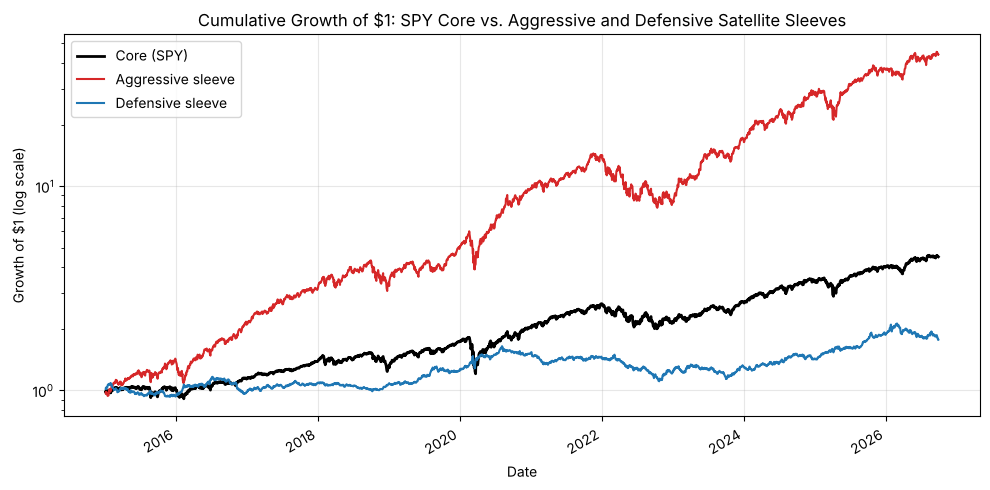

                    CAGR  Ann. volatility  Max drawdown  Beta vs SPY
Core (SPY)         0.137            0.175        -0.337        1.000
Aggressive sleeve  0.382            0.279        -0.458        1.374
Defensive sleeve   0.050            0.123        -0.327       -0.037


In [ ]:
#  Daily log returns 
log_returns = np.log(prices / prices.shift(1)).dropna()
print(f"Log returns: {log_returns.shape[0]} days x {log_returns.shape[1]} assets "
      f"(price rows: {prices.shape[0]})")

#  Sleeve returns (equal-weighted, rebalanced daily) 
simple_returns = np.exp(log_returns) - 1
sleeve_returns = pd.DataFrame({
    "Core (SPY)": simple_returns[CORE_TICKER],
    "Aggressive sleeve": simple_returns[AGGRESSIVE_TICKERS].mean(axis=1),
    "Defensive sleeve": simple_returns[DEFENSIVE_TICKERS].mean(axis=1),
})

#  Cumulative growth of $1 
cumulative_growth = (1 + sleeve_returns).cumprod()

colors = {"Core (SPY)": "black", "Aggressive sleeve": "tab:red", "Defensive sleeve": "tab:blue"}
fig, ax = plt.subplots(figsize=(10, 5))
for col in cumulative_growth.columns:
    cumulative_growth[col].plot(ax=ax, label=col, color=colors[col],
                                linewidth=2 if col == "Core (SPY)" else 1.5)

ax.set_title("Cumulative Growth of $1: SPY Core vs. Aggressive and Defensive Satellite Sleeves")
ax.set_xlabel("Date")
ax.set_ylabel("Growth of $1 (log scale)")
ax.set_yscale("log")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
os.makedirs("results/figures", exist_ok=True)
plt.savefig("results/figures/growth_core_aggressive_defensive.png", dpi=100)
plt.show()

#  Descriptive summary (full sample, exploratory only) 
ann = 252
n_years = len(sleeve_returns) / ann
spy = sleeve_returns["Core (SPY)"]
summary = pd.DataFrame({
    "CAGR": cumulative_growth.iloc[-1] ** (1 / n_years) - 1,
    "Ann. volatility": sleeve_returns.std() * np.sqrt(ann),
    "Max drawdown": (cumulative_growth / cumulative_growth.cummax() - 1).min(),
    "Beta vs SPY": sleeve_returns.apply(lambda s: s.cov(spy) / spy.var()),
})
print(summary.round(3))

## 4 Weekly Features

In [ ]:
#  Weekly SPY features (each value uses data up to Friday's close only) 
spy_close = prices[CORE_TICKER]
spy_volume = raw_data["Volume"][CORE_TICKER].reindex(prices.index)
daily_ret = np.log(spy_close).diff()

weekly = pd.DataFrame({
    "close": spy_close.resample("W-FRI").last(),
    "volume": spy_volume.resample("W-FRI").sum(),
})
weekly["ret_1w"] = np.log(weekly["close"]).diff()
weekly["ret_4w"] = np.log(weekly["close"]).diff(4)
weekly["ret_13w"] = np.log(weekly["close"]).diff(13)
weekly["rvol_1w"] = daily_ret.resample("W-FRI").std() * np.sqrt(252)
weekly["rvol_13w"] = weekly["ret_1w"].rolling(13).std() * np.sqrt(52)
weekly["dist_ma40w"] = np.log(weekly["close"] / weekly["close"].rolling(40).mean())
weekly["drawdown_52w"] = weekly["close"] / weekly["close"].rolling(52).max() - 1
weekly["volume_ratio"] = weekly["volume"] / weekly["volume"].rolling(13).mean()

#  Join weekly macro features 
macro_w = macro_d.resample("W-FRI").last().ffill()
weekly["y10"] = macro_w["y10"]
weekly["y10_chg_4w"] = macro_w["y10"].diff(4)
weekly["spread_10y2y"] = macro_w["spread_10y2y"]
weekly["fedfunds"] = macro_w["fedfunds"]
weekly["fedfunds_chg_13w"] = macro_w["fedfunds"].diff(13)

#  Final feature table 
weekly = weekly.loc[:END_DATE]                       # drop the partial final week
features = weekly.drop(columns=["close", "volume"]).dropna()
print(f"Features: {features.shape[0]} weeks x {features.shape[1]} variables")
print(f"Date range: {features.index.min().date()} to {features.index.max().date()}")
print(features.isna().sum().sum(), "missing values")
print(features.describe().T[["mean", "std", "min", "max"]].round(3))

Features: 562 weeks x 13 variables
Date range: 2015-12-25 to 2026-09-25
0 missing values
                   mean    std    min    max
ret_1w            0.003  0.023 -0.157  0.114
ret_4w            0.011  0.045 -0.371  0.225
ret_13w           0.035  0.069 -0.332  0.304
rvol_1w           0.137  0.114  0.010  1.293
rvol_13w          0.149  0.086  0.037  0.571
dist_ma40w        0.049  0.060 -0.275  0.162
drawdown_52w     -0.036  0.053 -0.318  0.000
volume_ratio      0.997  0.338  0.454  3.378
y10               2.816  1.219  0.550  5.170
y10_chg_4w        0.020  0.225 -0.850  0.720
spread_10y2y      0.391  0.564 -1.060  1.580
fedfunds          2.288  1.881  0.050  5.330
fedfunds_chg_13w  0.082  0.472 -1.540  2.000


## 5 Regime Discovery

In [ ]:
import torch, torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)

#  Regimes are defined from MARKET-STATE features only 
# Macro variables (yield change, curve, fed funds change) are slow-moving and episode-specific
# (e.g. the 2022 hiking cycle), so they are kept for the forecasting stage instead.
REGIME_FEATURES = ["ret_1w", "ret_4w", "ret_13w", "rvol_1w", "rvol_13w",
                   "dist_ma40w", "drawdown_52w", "volume_ratio"]
MACRO_FEATURES = ["y10_chg_4w", "spread_10y2y", "fedfunds_chg_13w"]   # used later to forecast regimes
X = features[REGIME_FEATURES]

#  Chronological split 70 / 15 / 15 
n = len(X); i_tr, i_va = int(n * 0.70), int(n * 0.85)
train_idx, val_idx, test_idx = X.index[:i_tr], X.index[i_tr:i_va], X.index[i_va:]
for name, idx in [("Train", train_idx), ("Validation", val_idx), ("Test", test_idx)]:
    print(f"{name:10s}: {len(idx)} weeks, {idx.min().date()} to {idx.max().date()}")

#  Scale using training data only 
scaler = StandardScaler().fit(X.loc[train_idx])
Z = pd.DataFrame(scaler.transform(X), index=X.index, columns=REGIME_FEATURES)
t = lambda idx: torch.tensor(Z.loc[idx].values, dtype=torch.float32)

Train     : 393 weeks, 2015-12-25 to 2023-06-30
Validation: 84 weeks, 2023-07-07 to 2025-02-07
Test      : 85 weeks, 2025-02-14 to 2026-09-25


In [ ]:
#  Autoencoder: 8 -> 6 -> 3 (latent) -> 6 -> 8 
N_LATENT = 3

class AutoEncoder(nn.Module):
    def __init__(self, n_in, n_hidden=6, n_latent=3):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(n_in, n_hidden), nn.ReLU(), nn.Linear(n_hidden, n_latent))
        self.dec = nn.Sequential(nn.Linear(n_latent, n_hidden), nn.ReLU(), nn.Linear(n_hidden, n_in))
    def forward(self, x):
        z = self.enc(x)
        return self.dec(z), z

model = AutoEncoder(len(REGIME_FEATURES), n_latent=N_LATENT)
print(f"Parameters: {sum(p.numel() for p in model.parameters())}")
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
loss_fn = nn.MSELoss()
Xtr, Xva = t(train_idx), t(val_idx)

best_val, best_state, wait, PATIENCE = np.inf, None, 0, 40
for epoch in range(1000):
    model.train(); opt.zero_grad()
    loss = loss_fn(model(Xtr)[0], Xtr); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        val = loss_fn(model(Xva)[0], Xva).item()
    if val < best_val - 1e-5:
        best_val, wait = val, 0
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        wait += 1
        if wait >= PATIENCE:
            break
model.load_state_dict(best_state)

# training loss of the RESTORED (best) weights, so both numbers describe the same model
model.eval()
with torch.no_grad():
    train_loss = loss_fn(model(Xtr)[0], Xtr).item()
print(f"Stopped at epoch {epoch} (best weights restored): "
      f"train loss {train_loss:.3f}, validation loss {best_val:.3f}")

Parameters: 155


Stopped at epoch 999 (best weights restored): train loss 0.150, validation loss 0.085


In [ ]:
#  Embeddings for all weeks 
model.eval()
with torch.no_grad():
    emb = pd.DataFrame(model(t(Z.index))[1].numpy(), index=Z.index)

#  Cluster, fitted on training embeddings only 
K = 2   # 3 was tried: the third regime ("Stressed") was ~1% of weeks (COVID only), too rare to forecast
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(emb.loc[train_idx])
raw = pd.Series(km.predict(emb), index=emb.index)

#  Order clusters by a market-stress score (training-period means of standardised features) 
zmeans = Z.loc[train_idx].groupby(raw.loc[train_idx]).mean()
stress_score = (zmeans["rvol_13w"] + zmeans["rvol_1w"]
                - zmeans["ret_13w"] - zmeans["dist_ma40w"] - zmeans["drawdown_52w"])
order = list(stress_score.sort_values().index)          # calmest first
REGIME_NAMES = ({0: "Trending", 1: "Normal", 2: "Stressed"} if K == 3
                else {0: "Trending", 1: "Stressed"})
regime = raw.map({c: i for i, c in enumerate(order)}).rename("regime")

print("Cluster stress scores (low = calm):")
print(pd.Series({REGIME_NAMES[i]: stress_score[c] for i, c in enumerate(order)}).round(2))

Cluster stress scores (low = calm):
Trending   -1.58
Stressed    6.50
dtype: float64


In [ ]:
#  Sanity checks 
split_sets = [("Train", train_idx), ("Validation", val_idx), ("Test", test_idx)]
print("\nShare of weeks in each regime:")
for name, idx in split_sets:
    s = regime.loc[idx].value_counts(normalize=True).reindex(range(K), fill_value=0)
    print(f"  {name:10s}: " + ", ".join(f"{REGIME_NAMES[k]} {s[k]:.0%}" for k in s.index))

episodes = {"2018 Q4 sell-off": ("2018-10-01", "2018-12-31"),
            "COVID crash":      ("2020-02-15", "2020-04-30"),
            "2022 bear market": ("2022-01-01", "2022-10-31")}
print("\nKnown stress episodes (share of weeks not Trending / share Stressed):")
for name, (a, b) in episodes.items():
    r = regime.loc[a:b]
    print(f"  {name:18s}: not Trending {(r > 0).mean():.0%}, Stressed {(r == K - 1).mean():.0%}")

print("\nMean feature values by regime (training period; macro shown for information only):")
print(features[REGIME_FEATURES + MACRO_FEATURES].loc[train_idx]
      .groupby(regime.loc[train_idx].map(REGIME_NAMES)).mean().T.round(3))

#  Trial log: one row per distinct configuration (re-running the same setup does not add a row) 
if "trial_log" not in globals():
    trial_log = []
row = {
    "features": len(REGIME_FEATURES), "latent": N_LATENT, "k": K,
    "val_loss": round(best_val, 3),
    **{f"{n.lower()}_stressed": round((regime.loc[i] == K - 1).mean(), 3) for n, i in split_sets},
    **{f"{n}_notTrending": round((regime.loc[a:b] > 0).mean(), 2) for n, (a, b) in episodes.items()},
}
if row not in trial_log:
    trial_log.append(row)
print("\nTrial log:")
print(pd.DataFrame(trial_log).to_string(index=False))


Share of weeks in each regime:
  Train     : Trending 80%, Stressed 20%
  Validation: Trending 96%, Stressed 4%
  Test      : Trending 89%, Stressed 11%

Known stress episodes (share of weeks not Trending / share Stressed):
  2018 Q4 sell-off  : not Trending 69%, Stressed 69%
  COVID crash       : not Trending 80%, Stressed 80%
  2022 bear market  : not Trending 70%, Stressed 70%

Mean feature values by regime (training period; macro shown for information only):
regime            Stressed  Trending
ret_1w              -0.017     0.007
ret_4w              -0.045     0.022
ret_13w             -0.068     0.052
rvol_1w              0.292     0.107
rvol_13w             0.249     0.132
dist_ma40w          -0.054     0.063
drawdown_52w        -0.133    -0.022
volume_ratio         1.273     0.937
y10_chg_4w          -0.005     0.021
spread_10y2y         0.199     0.581
fedfunds_chg_13w     0.298     0.127

Trial log:
 features  latent  k  val_loss  train_stressed  validation_stressed  test_st

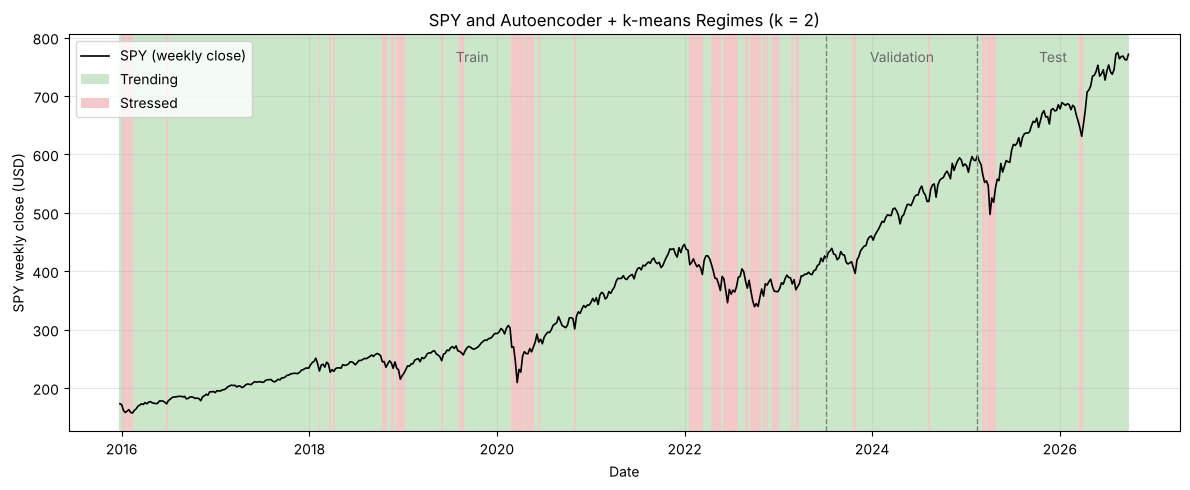

In [ ]:
#  SPY price with regime shading, split boundaries labelled 
from matplotlib.patches import Patch

REGIME_COLORS = {"Trending": "tab:green", "Stressed": "tab:red"}

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(weekly["close"].loc[regime.index], color="black", linewidth=1.2)

# shade each run of consecutive weeks in the same regime
runs = (regime != regime.shift()).cumsum()
for _, seg in regime.groupby(runs):
    start = seg.index[0] - pd.Timedelta(days=3)
    end = seg.index[-1] + pd.Timedelta(days=4)
    ax.axvspan(start, end, color=REGIME_COLORS[REGIME_NAMES[seg.iloc[0]]], alpha=0.25, linewidth=0)

# split boundaries and labels
for idx in (val_idx, test_idx):
    ax.axvline(idx[0], color="grey", linestyle="--", linewidth=1)
ymax = ax.get_ylim()[1]
for idx, label in [(train_idx, "Train"), (val_idx, "Validation"), (test_idx, "Test")]:
    ax.text(idx[len(idx) // 2], ymax * 0.97, label, ha="center", va="top", fontsize=10, color="dimgrey")

# legend
handles = [plt.Line2D([0], [0], color="black", lw=1.2, label="SPY (weekly close)")]
handles += [Patch(facecolor=c, alpha=0.25, label=name) for name, c in REGIME_COLORS.items()]
ax.legend(handles=handles, loc="upper left")

ax.set_title("SPY and Autoencoder + k-means Regimes (k = 2)")
ax.set_xlabel("Date")
ax.set_ylabel("SPY weekly close (USD)")
ax.grid(alpha=0.3)
plt.tight_layout()
os.makedirs("results/figures", exist_ok=True)
plt.savefig("results/figures/regimes_spy.png", dpi=100)
plt.show()

Trials run: k=3 (rejected: third regime ≈1% of weeks, COVID only), then k=2 (final). 11-feature version with macro features rejected: macro created an episode-specific cluster.

## 6 Regime Forecasting

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score, brier_score_loss

#  Forecasting dataset: features known at Friday t -> regime of week t+1 
data = features.copy()
data["regime_now"] = regime
data["stress_4w"] = regime.rolling(4).mean()          # share of Stressed weeks in the last 4
data["next_regime"] = regime.shift(-1)                # target (0 = Trending, 1 = Stressed)
data = data.dropna()

STATE_COLS = REGIME_FEATURES + ["regime_now", "stress_4w"]
FULL_COLS = STATE_COLS + MACRO_FEATURES               # adds macro predictors
tr = data.index.intersection(train_idx)
va = data.index.intersection(val_idx)
te = data.index.intersection(test_idx)
for name, idx in [("Train", tr), ("Validation", va), ("Test", te)]:
    print(f"{name:10s}: {len(idx)} weeks, next-week Stressed share {data.loc[idx, 'next_regime'].mean():.1%}")

Train     : 390 weeks, next-week Stressed share 19.2%
Validation: 84 weeks, next-week Stressed share 3.6%
Test      : 84 weeks, next-week Stressed share 10.7%


### 6.1 Baseline

In [ ]:
def score(y, p, thr=0.5):
    """Probability metrics plus hard-label metrics at threshold thr."""
    pred = (p >= thr).astype(int)
    return {"AUC": roc_auc_score(y, p) if len(set(y)) > 1 else np.nan,
            "Brier": brier_score_loss(y, p),
            "BalAcc": balanced_accuracy_score(y, pred),
            "F1_stressed": f1_score(y, pred, zero_division=0)}

rows = []
def evaluate(label, prob_by_split):
    for split, idx in [("Validation", va), ("Test", te)]:
        rows.append({"model": label, "split": split,
                     **score(data.loc[idx, "next_regime"].values, prob_by_split[split])})

#  Baseline: persistence (next week = this week) 
evaluate("Persistence (0/1)", {"Validation": data.loc[va, "regime_now"].values,
                         "Test": data.loc[te, "regime_now"].values})



In [ ]:
#  Probabilistic persistence baselines (scored like the models, on AUC and Brier) 
# A 0/1 forecast scores AUC = balanced accuracy and Brier = error rate by construction, so it is not a fair
# comparison with probability forecasts. Two probabilistic versions, both using training information only:
#  - transition probability P(Stressed next week | regime this week), estimated on training weeks
#  - share of Stressed weeks in the last four weeks (stress_4w)
P_tr = pd.crosstab(data.loc[tr, "regime_now"], data.loc[tr, "next_regime"], normalize="index")
print("Training transition matrix (rows: this week, columns: next week):")
print(P_tr.rename(index=REGIME_NAMES, columns=REGIME_NAMES).round(3).to_string())
for k in P_tr.index:
    print(f"Expected {REGIME_NAMES[k]} spell: {1 / (1 - P_tr.loc[k, k]):.1f} weeks")
evaluate("Persistence (transition prob.)",
         {s: data.loc[i, "regime_now"].map(P_tr[1]).values for s, i in [("Validation", va), ("Test", te)]})
evaluate("Share Stressed, last 4 weeks",
         {s: data.loc[i, "stress_4w"].values for s, i in [("Validation", va), ("Test", te)]})

Training transition matrix (rows: this week, columns: next week):
next_regime  Trending  Stressed
regime_now                     
Trending        0.927     0.073
Stressed        0.316     0.684
Expected Trending spell: 13.7 weeks
Expected Stressed spell: 3.2 weeks


### 6.2 Logistic

In [ ]:
#  Logistic regression, with and without macro predictors (scaler fitted on train only) 
def fit_logit(cols, label):
    sc = StandardScaler().fit(data.loc[tr, cols])
    clf = LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000, random_state=SEED)
    clf.fit(sc.transform(data.loc[tr, cols]), data.loc[tr, "next_regime"])
    probs = {s: clf.predict_proba(sc.transform(data.loc[i, cols]))[:, 1]
             for s, i in [("Validation", va), ("Test", te)]}
    evaluate(label, probs)
    return clf, sc, probs

logit_state = fit_logit(STATE_COLS, "Logit (balanced): market-state")
logit_full = fit_logit(FULL_COLS, "Logit (balanced): market-state + macro")

results = pd.DataFrame(rows).round(3)
print("\nNext-week regime forecasts (decide on Validation; Test is the final out-of-sample check):")
print(results.sort_values(["split", "model"]).to_string(index=False))


Next-week regime forecasts (decide on Validation; Test is the final out-of-sample check):
                                 model      split   AUC  Brier  BalAcc  F1_stressed
        Logit (balanced): market-state       Test 0.967  0.077   0.953        0.720
Logit (balanced): market-state + macro       Test 0.963  0.082   0.960        0.750
                     Persistence (0/1)       Test 0.813  0.071   0.813        0.667
        Persistence (transition prob.)       Test 0.813  0.059   0.813        0.667
          Share Stressed, last 4 weeks       Test 0.838  0.077   0.731        0.476
        Logit (balanced): market-state Validation 0.938  0.061   0.630        0.200
Logit (balanced): market-state + macro Validation 0.914  0.109   0.759        0.235
                     Persistence (0/1) Validation 0.654  0.048   0.654        0.333
        Persistence (transition prob.) Validation 0.654  0.038   0.654        0.333
          Share Stressed, last 4 weeks Validation 0.611  0.043   0.48

### 6.3 XGBoost

In [ ]:
from xgboost import XGBClassifier

#  Unweighted logistic regression (probabilities are comparable with persistence on Brier) 
def fit_logit_plain(cols, label):
    sc = StandardScaler().fit(data.loc[tr, cols])
    clf = LogisticRegression(C=1.0, max_iter=2000, random_state=SEED)
    clf.fit(sc.transform(data.loc[tr, cols]), data.loc[tr, "next_regime"])
    probs = {s: clf.predict_proba(sc.transform(data.loc[i, cols]))[:, 1]
             for s, i in [("Validation", va), ("Test", te)]}
    evaluate(label, probs)
    return clf, sc, probs

logit_plain = fit_logit_plain(STATE_COLS, "Logit (unweighted): market-state")
logit_plain_full = fit_logit_plain(FULL_COLS, "Logit (unweighted): market-state + macro")   # same weighting as above

#  XGBoost: shallow trees, fixed settings chosen in advance (no tuning on validation/test) 
xgb = XGBClassifier(n_estimators=200, max_depth=2, learning_rate=0.05, subsample=0.8,
                    colsample_bytree=0.8, reg_lambda=1.0, eval_metric="logloss",
                    random_state=SEED)
xgb.fit(data.loc[tr, STATE_COLS], data.loc[tr, "next_regime"])
xgb_probs = {s: xgb.predict_proba(data.loc[i, STATE_COLS])[:, 1]
             for s, i in [("Validation", va), ("Test", te)]}
evaluate("XGBoost: market-state", xgb_probs)

results = pd.DataFrame(rows).drop_duplicates().round(3)
print("Next-week regime forecasts (decide on Validation; Test is the final out-of-sample check):")
print(results.sort_values(["split", "model"]).to_string(index=False))

#  Which features drive the XGBoost forecast? 
imp = pd.Series(xgb.feature_importances_, index=STATE_COLS).sort_values(ascending=False)
print("\nXGBoost feature importance:")
print(imp.round(3).to_string())

Next-week regime forecasts (decide on Validation; Test is the final out-of-sample check):
                                   model      split   AUC  Brier  BalAcc  F1_stressed
          Logit (balanced): market-state       Test 0.967  0.077   0.953        0.720
  Logit (balanced): market-state + macro       Test 0.963  0.082   0.960        0.750
        Logit (unweighted): market-state       Test 0.967  0.048   0.702        0.500
Logit (unweighted): market-state + macro       Test 0.963  0.050   0.702        0.500
                       Persistence (0/1)       Test 0.813  0.071   0.813        0.667
          Persistence (transition prob.)       Test 0.813  0.059   0.813        0.667
            Share Stressed, last 4 weeks       Test 0.838  0.077   0.731        0.476
                   XGBoost: market-state       Test 0.976  0.041   0.862        0.700
          Logit (balanced): market-state Validation 0.938  0.061   0.630        0.200
  Logit (balanced): market-state + macro Validatio

### 6.4 Backtest (weekly-reset version; superseded by the simulator in 6.8)

In [ ]:
#  Weekly returns of the three building blocks; each signal at Friday t earns the NEXT week's return 
COST_BPS = 5                                   # per unit of one-way traded notional
W_CORE, W_SAT = CORE_WEIGHT, SATELLITE_WEIGHT

wk = ((1 + sleeve_returns).resample("W-FRI").prod() - 1).loc[:END_DATE]
wk_next = wk.shift(-1)                         # return over the week after the signal date

def backtest(idx, stressed):
    """stressed: 0/1 Series on idx. 1 = hold the defensive sleeve during the next week."""
    r = wk_next.loc[idx]
    sat = np.where(stressed.values == 1, r["Defensive sleeve"], r["Aggressive sleeve"])
    gross = W_CORE * r["Core (SPY)"] + W_SAT * sat
    switch = stressed.diff().abs().fillna(0)   # 1 in a week the satellite sleeve changes
    cost = switch * (2 * W_SAT) * COST_BPS / 1e4   # a switch trades sell 50% + buy 50%
    return gross - cost, switch

# Risk-free rate: 3-month T-bill (FRED DGS3MO, annualised %), converted to a weekly rate known at the signal date
rf_w = ((1 + snap_macro["tbill_3m"].ffill() / 100) ** (1 / 52) - 1).resample("W-FRI").last().ffill()

def excess(ret):
    """Weekly return in excess of the T-bill rate for the same week."""
    return ret - rf_w.reindex(ret.index).fillna(0)

def ann_turnover(traded):
    """Annualised ONE-WAY turnover: half the traded notional (sum of |weight changes|) per year."""
    return traded.sum() / 2 / (len(traded) / 52)

def metrics(ret, switch=None):
    n = len(ret); equity = (1 + ret).cumprod()
    return {"Ann. return": equity.iloc[-1] ** (52 / n) - 1,
            "Ann. vol": ret.std() * np.sqrt(52),
            "Sharpe": excess(ret).mean() / excess(ret).std() * np.sqrt(52),   # excess-return Sharpe ratio
            "Max drawdown": (equity / equity.cummax() - 1).min(),
            "Switches": int(switch.sum()) if switch is not None else 0}

def run_all(split, idx, thr):
    r = wk_next.loc[idx]
    sigs = {
        f"Logit forecast (thr {thr})":   (pd.Series(logit_plain[2][split], index=idx) >= thr).astype(int),
        f"XGBoost forecast (thr {thr})": (pd.Series(xgb_probs[split], index=idx) >= thr).astype(int),
        "Persistence signal":            data.loc[idx, "regime_now"].astype(int),
        "Oracle (perfect foresight)":    data.loc[idx, "next_regime"].astype(int),
    }
    out = {}
    for name, s in sigs.items():
        ret, sw = backtest(idx, s)
        out[name] = {**metrics(ret, sw), "% weeks defensive": s.mean()}
    static = {
        "SPY buy-and-hold":           r["Core (SPY)"],
        "Static 50% SPY + 50% Aggr.": 0.5 * r["Core (SPY)"] + 0.5 * r["Aggressive sleeve"],
        "Static 50% SPY + 50% Def.":  0.5 * r["Core (SPY)"] + 0.5 * r["Defensive sleeve"],
        "Static 50/25/25 blend":      0.5 * r["Core (SPY)"] + 0.25 * r["Aggressive sleeve"] + 0.25 * r["Defensive sleeve"],
    }
    for name, ret in static.items():
        out[name] = metrics(ret)
    return pd.DataFrame(out).T



In [ ]:
#  1) Choose the probability threshold on VALIDATION only (small fixed grid) 
GRID = [0.2, 0.3, 0.4, 0.5]
grid_rows = []
for thr in GRID:
    s = (pd.Series(logit_plain[2]["Validation"], index=va) >= thr).astype(int)
    ret, sw = backtest(va, s)
    grid_rows.append({"threshold": thr, **metrics(ret, sw), "% weeks defensive": s.mean()})
grid = pd.DataFrame(grid_rows).set_index("threshold")
print("Threshold selection (validation, logit forecast):")
print(grid.round(3))
THR = grid["Sharpe"].idxmax()
print(f"\nChosen threshold: {THR}")

#  2) Report both periods with that threshold 
fmt = {"Ann. return": "{:.1%}", "Ann. vol": "{:.1%}", "Sharpe": "{:.2f}",
       "Max drawdown": "{:.1%}", "% weeks defensive": "{:.0%}"}
for split, idx in [("Validation", va), ("Test", te)]:
    res = run_all(split, idx, THR)
    print(f"\n=== {split}: {idx.min().date()} to {idx.max().date()} ({len(idx)} weeks, cost {COST_BPS} bps) ===")
    print(res.round(3).to_string())
    os.makedirs("results", exist_ok=True)
    res.round(4).to_csv(f"results/backtest_{split.lower()}.csv")

Threshold selection (validation, logit forecast):
           Ann. return  Ann. vol  Sharpe  Max drawdown  Switches  \
threshold                                                          
0.2              0.339     0.173   1.485        -0.102         8   
0.3              0.369     0.174   1.601        -0.106         4   
0.4              0.389     0.174   1.688        -0.085         2   
0.5              0.372     0.175   1.606        -0.102         2   

           % weeks defensive  
threshold                     
0.2                    0.083  
0.3                    0.036  
0.4                    0.024  
0.5                    0.012  

Chosen threshold: 0.4

=== Validation: 2023-07-07 to 2025-02-07 (84 weeks, cost 5 bps) ===
                            Ann. return  Ann. vol  Sharpe  Max drawdown  Switches  % weeks defensive
Logit forecast (thr 0.4)          0.389     0.174   1.688        -0.085       2.0              0.024
XGBoost forecast (thr 0.4)        0.369     0.174   1.601    

### 6.5 Diagnostics and sensitivity

In [ ]:
#  1) Do the regime labels separate the sleeves' payoffs? (mean NEXT-week return, % per week) 
d = pd.DataFrame({"next_regime": data["next_regime"],
                  "SPY": wk_next["Core (SPY)"].reindex(data.index),
                  "Aggressive": wk_next["Aggressive sleeve"].reindex(data.index),
                  "Defensive": wk_next["Defensive sleeve"].reindex(data.index)})
d["split"] = np.where(d.index.isin(tr), "Train", np.where(d.index.isin(va), "Validation", "Test"))
g = d.groupby(["split", "next_regime"])
payoff = (g[["SPY", "Aggressive", "Defensive"]].mean() * 100).round(2)
payoff["weeks"] = g.size()
print("Mean weekly return by next-week regime (0 = Trending, 1 = Stressed), %:")
print(payoff.loc[["Train", "Validation", "Test"]])

#  2) Continuous version of the backtest: s = weight of the DEFENSIVE sleeve inside the satellite 
def backtest_w(idx, s):
    r = wk_next.loc[idx]
    sat = (1 - s.values) * r["Aggressive sleeve"] + s.values * r["Defensive sleeve"]
    gross = W_CORE * r["Core (SPY)"] + W_SAT * sat
    turnover = s.diff().abs().fillna(0)              # share of the satellite moved between sleeves
    return gross - turnover * (2 * W_SAT) * COST_BPS / 1e4, turnover

#  3) Sensitivity: threshold grid vs probability-weighted blend (reference, NOT for selection on Test) 
rows_s = []
for split, idx in [("Validation", va), ("Test", te)]:
    r = wk_next.loc[idx]
    for mname, P in [("Logit", logit_plain[2]), ("XGBoost", xgb_probs)]:
        p = pd.Series(P[split], index=idx)
        rules = {f"thr {t}": (p >= t).astype(float) for t in [0.1, 0.2, 0.3, 0.4, 0.5]}
        rules["prob-weighted"] = p
        for rname, s in rules.items():
            ret, to = backtest_w(idx, s)
            m = metrics(ret); m.pop("Switches")
            rows_s.append({"split": split, "strategy": f"{mname} | {rname}", **m,
                           "avg def. weight": s.mean(), "Turnover (ann., one-way)": ann_turnover(to * 2 * W_SAT)})
    # references
    ret, to = backtest_w(idx, data.loc[idx, "regime_now"].astype(float))
    m = metrics(ret); m.pop("Switches")
    rows_s.append({"split": split, "strategy": "Persistence signal", **m,
                   "avg def. weight": data.loc[idx, "regime_now"].mean(), "Turnover (ann., one-way)": ann_turnover(to * 2 * W_SAT)})
    for name, ret in {"Static 50/25/25 blend": 0.5*r["Core (SPY)"] + 0.25*r["Aggressive sleeve"] + 0.25*r["Defensive sleeve"],
                      "Static 50% SPY + 50% Aggr.": 0.5*r["Core (SPY)"] + 0.5*r["Aggressive sleeve"]}.items():
        m = metrics(ret); m.pop("Switches")
        rows_s.append({"split": split, "strategy": name, **m, "avg def. weight": np.nan, "Turnover (ann., one-way)": 0.0})

sens = pd.DataFrame(rows_s).set_index(["split", "strategy"]).round(3)
print("\nSensitivity of the strategy to the signal rule (transaction cost %d bps):" % COST_BPS)
print(sens.to_string())
os.makedirs("results", exist_ok=True)
sens.to_csv("results/sensitivity_rules.csv")

Mean weekly return by next-week regime (0 = Trending, 1 = Stressed), %:
                         SPY  Aggressive  Defensive  weeks
split      next_regime                                    
Train      0.0          0.73        1.38       0.02    315
           1.0         -1.59       -2.13       0.31     75
Validation 0.0          0.51        1.01       0.25     81
           1.0         -1.62       -1.27      -0.34      3
Test       0.0          0.51        0.77       0.27     75
           1.0         -1.23       -1.05      -0.06      9

Sensitivity of the strategy to the signal rule (transaction cost 5 bps):
                                       Ann. return  Ann. vol  Sharpe  Max drawdown  avg def. weight  Turnover (ann., one-way)
split      strategy                                                                                                          
Validation Logit | thr 0.1                   0.244     0.162   1.116        -0.101            0.179                     4.333
    

### 6.6 Theoretic threshold

In [ ]:
#  Break-even threshold from TRAINING payoffs only 
trn = d[d["split"] == "Train"]
gap_trend = (trn.loc[trn.next_regime == 0, "Aggressive"] - trn.loc[trn.next_regime == 0, "Defensive"]).mean()
gap_stress = (trn.loc[trn.next_regime == 1, "Defensive"] - trn.loc[trn.next_regime == 1, "Aggressive"]).mean()
THR_DT = gap_trend / (gap_trend + gap_stress)
print(f"Cost of a false alarm (Trending week): {gap_trend:.2%}/wk | gain from a correct alarm (Stressed week): {gap_stress:.2%}/wk")
print(f"Break-even threshold from training payoffs: {THR_DT:.2f}")

#  Paired block bootstrap on the annualised mean weekly return difference 
def block_boot_ci(diff, block=4, n_boot=5000, seed=SEED):
    rng = np.random.default_rng(seed)
    x = diff.values; n = len(x); nb = int(np.ceil(n / block))
    means = np.empty(n_boot)
    for b in range(n_boot):
        starts = rng.integers(0, n - block + 1, nb)
        means[b] = np.concatenate([x[s:s + block] for s in starts])[:n].mean()
    return np.percentile(means, [2.5, 97.5]) * 52

rows_m, rows_b = [], []
for split, idx in [("Validation", va), ("Test", te)]:
    r = wk_next.loc[idx]
    static_aggr = 0.5 * r["Core (SPY)"] + 0.5 * r["Aggressive sleeve"]
    static_blend = 0.5 * r["Core (SPY)"] + 0.25 * r["Aggressive sleeve"] + 0.25 * r["Defensive sleeve"]
    refs = {"Static 50% SPY + 50% Aggr.": static_aggr, "Static 50/25/25 blend": static_blend,
            "SPY buy-and-hold": r["Core (SPY)"]}
    for mname, P in [("Logit", logit_plain[2]), ("XGBoost", xgb_probs)]:
        s = (pd.Series(P[split], index=idx) >= THR_DT).astype(float)
        ret, to = backtest_w(idx, s)
        m = metrics(ret); m.pop("Switches")
        rows_m.append({"split": split, "strategy": f"{mname} forecast (thr {THR_DT:.2f})", **m,
                       "% weeks defensive": s.mean(), "switches": to.sum()})
        for rname in ["Static 50% SPY + 50% Aggr.", "Static 50/25/25 blend"]:
            lo, hi = block_boot_ci(ret - refs[rname])
            rows_b.append({"split": split, "strategy": f"{mname}", "vs": rname,
                           "ann. return diff": (ret - refs[rname]).mean() * 52, "95% CI low": lo, "95% CI high": hi})
    ret, to = backtest_w(idx, data.loc[idx, "regime_now"].astype(float))
    m = metrics(ret); m.pop("Switches")
    rows_m.append({"split": split, "strategy": "Persistence signal", **m,
                   "% weeks defensive": data.loc[idx, "regime_now"].mean(), "switches": to.sum()})
    for name, ret in refs.items():
        m = metrics(ret); m.pop("Switches")
        rows_m.append({"split": split, "strategy": name, **m, "% weeks defensive": np.nan, "switches": 0})

final_tbl = pd.DataFrame(rows_m).set_index(["split", "strategy"]).round(3)
boot_tbl = pd.DataFrame(rows_b).set_index(["split", "strategy", "vs"]).round(3)
print("\nPerformance at the break-even threshold (cost %d bps):" % COST_BPS)
print(final_tbl.to_string())
print("\nAnnualised return difference vs static benchmarks, 95% block-bootstrap CI:")
print(boot_tbl.to_string())
final_tbl.to_csv("results/backtest_final.csv"); boot_tbl.to_csv("results/backtest_bootstrap.csv")

Cost of a false alarm (Trending week): 1.36%/wk | gain from a correct alarm (Stressed week): 2.44%/wk
Break-even threshold from training payoffs: 0.36



Performance at the break-even threshold (cost 5 bps):
                                        Ann. return  Ann. vol  Sharpe  Max drawdown  % weeks defensive  switches
split      strategy                                                                                             
Validation Logit forecast (thr 0.36)          0.389     0.174   1.688        -0.085              0.024       2.0
           XGBoost forecast (thr 0.36)        0.369     0.174   1.601        -0.106              0.036       4.0
           Persistence signal                 0.368     0.171   1.629        -0.086              0.036       4.0
           Static 50% SPY + 50% Aggr.         0.399     0.181   1.671        -0.102                NaN       0.0
           Static 50/25/25 blend              0.289     0.133   1.598        -0.091                NaN       0.0
           SPY buy-and-hold                   0.242     0.128   1.363        -0.098                NaN       0.0
Test       Logit forecast (thr 0.36)     

### 6.7 LSTM

In [ ]:
#  LSTM: last L weekly feature vectors -> probability the NEXT week is Stressed 
torch.manual_seed(SEED); np.random.seed(SEED)
L = 8                                                     # look-back window in weeks (fixed in advance)
sc_seq = StandardScaler().fit(data.loc[tr, STATE_COLS])  # scaler fitted on training weeks only
A = sc_seq.transform(data[STATE_COLS]).astype(np.float32)
pos = {d_: i for i, d_ in enumerate(data.index)}
y_all = data["next_regime"].values.astype(np.float32)

def make_seq(idx):
    ii = np.array([pos[x] for x in idx]); ii = ii[ii >= L - 1]      # need L weeks of history
    Xs = torch.tensor(np.stack([A[i - L + 1:i + 1] for i in ii]))
    return Xs, torch.tensor(y_all[ii]), ii

Xtr_s, ytr_s, _ = make_seq(tr)
Xva_s, yva_s, _ = make_seq(va)
Xte_s, yte_s, _ = make_seq(te)

class SeqNet(nn.Module):
    def __init__(self, n_in, hidden=16):
        super().__init__()
        self.lstm = nn.LSTM(n_in, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1]).squeeze(-1)             # logit of P(next week Stressed)

net = SeqNet(len(STATE_COLS))
print("LSTM parameters:", sum(p.numel() for p in net.parameters()))
opt_s = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
bce = nn.BCEWithLogitsLoss()                                 # unweighted: probabilities stay calibrated

lstm_best, lstm_state, lstm_wait = np.inf, None, 0
for epoch_s in range(600):
    net.train(); opt_s.zero_grad()
    bce(net(Xtr_s), ytr_s).backward(); opt_s.step()
    net.eval()
    with torch.no_grad():
        v = bce(net(Xva_s), yva_s).item()
    if v < lstm_best - 1e-4:
        lstm_best, lstm_wait = v, 0
        lstm_state = {k: t_.clone() for k, t_ in net.state_dict().items()}
    else:
        lstm_wait += 1
        if lstm_wait >= 40:
            break
net.load_state_dict(lstm_state); net.eval()
print(f"Stopped at epoch {epoch_s}; best validation log-loss {lstm_best:.3f}")

with torch.no_grad():
    lstm_probs = {"Validation": torch.sigmoid(net(Xva_s)).numpy(),
                  "Test": torch.sigmoid(net(Xte_s)).numpy()}
evaluate("LSTM: market-state", lstm_probs)
results = pd.DataFrame(rows).drop_duplicates().round(3)
print("\nForecast quality (all models):")
print(results.sort_values(["split", "model"]).to_string(index=False))

#  Backtest at the same break-even threshold as the other models 
rows_l = []
for split, idx in [("Validation", va), ("Test", te)]:
    s = (pd.Series(lstm_probs[split], index=idx) >= THR_DT).astype(float)
    ret, to = backtest_w(idx, s)
    m = metrics(ret); m.pop("Switches")
    rows_l.append({"split": split, "strategy": f"LSTM forecast (thr {THR_DT:.2f})", **m,
                   "% weeks defensive": s.mean(), "switches": to.sum()})
lstm_tbl = pd.DataFrame(rows_l).set_index(["split", "strategy"]).round(3)
print("\nLSTM strategy (compare with the XGBoost, logit and static rows above):")
print(lstm_tbl.to_string())
lstm_tbl.to_csv("results/backtest_lstm.csv")

LSTM parameters: 1809


Stopped at epoch 283; best validation log-loss 0.140

Forecast quality (all models):
                                   model      split   AUC  Brier  BalAcc  F1_stressed
                      LSTM: market-state       Test 0.945  0.056   0.758        0.588
          Logit (balanced): market-state       Test 0.967  0.077   0.953        0.720
  Logit (balanced): market-state + macro       Test 0.963  0.082   0.960        0.750
        Logit (unweighted): market-state       Test 0.967  0.048   0.702        0.500
Logit (unweighted): market-state + macro       Test 0.963  0.050   0.702        0.500
                       Persistence (0/1)       Test 0.813  0.071   0.813        0.667
          Persistence (transition prob.)       Test 0.813  0.059   0.813        0.667
            Share Stressed, last 4 weeks       Test 0.838  0.077   0.731        0.476
                   XGBoost: market-state       Test 0.976  0.041   0.862        0.700
                      LSTM: market-state Validation 0.9

In [ ]:
#  Hard-label quality at the operating threshold THR_DT (the rule the portfolio actually uses) 
from sklearn.metrics import precision_score, recall_score
op_rows = []
for split, idx in [("Validation", va), ("Test", te)]:
    y = data.loc[idx, "next_regime"].astype(int).values
    now = data.loc[idx, "regime_now"].astype(int).values
    cands = {"Persistence (0/1)": now, "Logit (unweighted)": logit_plain[2][split],
             "XGBoost": xgb_probs[split], "LSTM": lstm_probs[split],
             "Rule: SPY below 40w MA": (data.loc[idx, "dist_ma40w"] < 0).astype(int).values}
    for name, p in cands.items():
        pred = (np.asarray(p) >= THR_DT).astype(int)
        op_rows.append({"split": split, "model": name,
                        "BalAcc": balanced_accuracy_score(y, pred),
                        "Precision": precision_score(y, pred, zero_division=0),
                        "Recall": recall_score(y, pred, zero_division=0),
                        "Signals Stressed": int(pred.sum()), "Actual Stressed": int(y.sum()),
                        "Weeks differing from regime_now": int((pred != now).sum())})
op_tbl = pd.DataFrame(op_rows).set_index(["split", "model"]).round(3)
print(f"Hard-label forecast quality at the operating threshold {THR_DT:.2f}:")
print(op_tbl.to_string())
op_tbl.to_csv("results/forecast_operating_threshold.csv")

Hard-label forecast quality at the operating threshold 0.36:
                                   BalAcc  Precision  Recall  Signals Stressed  Actual Stressed  Weeks differing from regime_now
split      model                                                                                                                
Validation Persistence (0/1)        0.654      0.333   0.333                 3                3                                0
           Logit (unweighted)       0.660      0.500   0.333                 2                3                                1
           XGBoost                  0.654      0.333   0.333                 3                3                                2
           LSTM                     0.488      0.000   0.000                 2                3                                3
           Rule: SPY below 40w MA   0.660      0.500   0.333                 2                3                                1
Test       Persistence (0/1)        

### 6.8 Cost, execution lag and rule based baseline

In [ ]:
#  Portfolio simulator with drifting weights, signal switches and a rebalance band 
def simulate(idx, T, r, bps, band=REBALANCE_BAND):
    """T: DataFrame (idx x [core, aggr, def]) of TARGET weights for each week.
    r: weekly returns with columns 'Core (SPY)', 'Aggressive sleeve', 'Defensive sleeve'.
    Rules: a change in the target mix moves the satellite between sleeves (core untouched);
    if the core weight drifts more than `band` from its target, everything resets to target.
    Cost = bps x traded notional (sum of |weight changes|)."""
    R = r[["Core (SPY)", "Aggressive sleeve", "Defensive sleeve"]].values
    Tv = T[["core", "aggr", "def"]].values
    w = Tv[0].copy()                               # initial purchase not charged (same for all strategies)
    rets, turn, n_band = [], [], 0
    for i in range(len(idx)):
        tgt, w_old = Tv[i], w.copy()
        if i > 0 and not np.allclose(tgt, Tv[i - 1]):          # signal changed the satellite mix
            sat, tsat = w[1] + w[2], tgt[1] + tgt[2]
            if tsat > 0:
                w = np.array([w[0], sat * tgt[1] / tsat, sat * tgt[2] / tsat])
        if abs(w[0] - tgt[0]) > band:                           # core/satellite drift beyond the band
            w = tgt.copy(); n_band += 1
        traded = np.abs(w - w_old).sum()
        rets.append(w @ R[i] - traded * bps / 1e4)
        turn.append(traded)
        w = w * (1 + R[i]); w = w / w.sum()                     # weights drift over the week
    return pd.Series(rets, index=idx), pd.Series(turn, index=idx), n_band

def targets_from_signal(s):
    """s: 0/1 Series (1 = defensive sleeve). Core fixed, satellite goes to the chosen sleeve."""
    return pd.DataFrame({"core": CORE_WEIGHT, "aggr": SATELLITE_WEIGHT * (1 - s.values),
                         "def": SATELLITE_WEIGHT * s.values}, index=s.index)

def static_ret(idx, r, core, aggr, dfn, bps=COST_BPS):
    """Static mix that follows the same drift + band rule (and pays the same costs)."""
    T = pd.DataFrame({"core": core, "aggr": aggr, "def": dfn}, index=idx)
    return simulate(idx, T, r, bps)[0]

#  sanity checks on the rebalance rule (test period) 
_T = pd.DataFrame({"core": 0.5, "aggr": 0.5, "def": 0.0}, index=te)
_, tv, nb = simulate(te, _T, wk_next.loc[te], COST_BPS)
_, tv0, nb0 = simulate(te, _T, wk_next.loc[te], COST_BPS, band=0.0)
print(f"Static 50/50, band {REBALANCE_BAND:.0%}: {nb} band rebalances, total turnover {tv.sum():.2f}")
print(f"Static 50/50, rebalanced every week (band 0): total turnover {tv0.sum():.2f}")

Static 50/50, band 10%: 0 band rebalances, total turnover 0.00
Static 50/50, rebalanced every week (band 0): total turnover 0.60


In [ ]:
def bt(idx, s, r, bps):
    """Signal strategy under the drift + band rule. Returns (net weekly returns, weekly turnover)."""
    ret, turn, _ = simulate(idx, targets_from_signal(s), r, bps)
    return ret, turn

# Execution lag: signal at Friday close, trade at MONDAY close, hold to the following Monday close
wl = (1 + sleeve_returns).resample("W-MON").prod() - 1
def returns_for(idx, lag):
    if not lag:
        return wk_next.loc[idx]                          # trade at the signal-day close (optimistic)
    return pd.DataFrame(wl.reindex(idx + pd.Timedelta(days=10)).values, index=idx, columns=wl.columns)

#  1) Cost x execution sensitivity for the forecast strategies 
rows_c = []
for split, idx in [("Validation", va), ("Test", te)]:
    for mname, P in [("Logit", logit_plain[2]), ("XGBoost", xgb_probs)]:
        s = (pd.Series(P[split], index=idx) >= THR_DT).astype(float)
        for lag in (False, True):
            r = returns_for(idx, lag)
            for bps in (0, 5, 10, 25, 50):
                ret, to = bt(idx, s, r, bps)
                m = metrics(ret)
                rows_c.append({"split": split, "model": mname, "execution": "Mon close" if lag else "Fri close",
                               "bps": bps, "Sharpe": m["Sharpe"], "Ann. return": m["Ann. return"]})
cost_df = pd.DataFrame(rows_c)
print("Sharpe by cost (bps per unit traded) and execution timing:")
print(cost_df.pivot_table(index=["split", "model", "execution"], columns="bps", values="Sharpe").round(2).to_string())
print("\nAnnualised return:")
print(cost_df.pivot_table(index=["split", "model", "execution"], columns="bps", values="Ann. return").round(3).to_string())



Sharpe by cost (bps per unit traded) and execution timing:
bps                             0     5     10    25    50
split      model   execution                              
Test       Logit   Fri close  1.17  1.17  1.16  1.14  1.10
                   Mon close  1.10  1.10  1.09  1.07  1.04
           XGBoost Fri close  1.12  1.11  1.10  1.07  1.03
                   Mon close  1.02  1.02  1.01  0.99  0.95
Validation Logit   Fri close  1.69  1.69  1.68  1.67  1.65
                   Mon close  1.65  1.65  1.64  1.63  1.62
           XGBoost Fri close  1.60  1.60  1.59  1.57  1.53
                   Mon close  1.64  1.63  1.63  1.61  1.57

Annualised return:
bps                              0      5      10     25     50
split      model   execution                                   
Test       Logit   Fri close  0.246  0.244  0.243  0.238  0.230
                   Mon close  0.232  0.231  0.229  0.225  0.217
           XGBoost Fri close  0.229  0.227  0.226  0.221  0.213
           

In [ ]:
#  2) Rule-based baselines (no ML), with the same costs, the same execution timing and the same rebalance rule 
vol_cut = data.loc[tr, "rvol_13w"].quantile(0.80)        # fixed from training data (~ base rate of Stressed weeks)
print(f"\nVol rule cut-off (training 80th percentile of rvol_13w): {vol_cut:.3f}")
rows_r = []
for split, idx in [("Validation", va), ("Test", te)]:
    for lag in (False, True):
        r = returns_for(idx, lag)
        sigs = {
            "XGBoost forecast": (pd.Series(xgb_probs[split], index=idx) >= THR_DT).astype(float),
            "Logit forecast": (pd.Series(logit_plain[2][split], index=idx) >= THR_DT).astype(float),
            "Rule: SPY below 40w MA": (data.loc[idx, "dist_ma40w"] < 0).astype(float),
            "Rule: 13w vol above cut-off": (data.loc[idx, "rvol_13w"] > vol_cut).astype(float),
        }
        for name, s in sigs.items():
            ret, to = bt(idx, s, r, COST_BPS)
            m = metrics(ret); m["Switches"] = int(s.diff().abs().fillna(0).sum()); m["Turnover (ann., one-way)"] = ann_turnover(to)
            rows_r.append({"split": split, "execution": "Mon close" if lag else "Fri close", "strategy": name, **m,
                           "% defensive": s.mean()})
        for name, ret in {"Static 50% SPY + 50% Aggr.": static_ret(idx, r, 0.5, 0.5, 0.0),
                          "Static 50/25/25 blend":      static_ret(idx, r, 0.5, 0.25, 0.25),
                          "SPY buy-and-hold":           static_ret(idx, r, 1.0, 0.0, 0.0)}.items():
            m = metrics(ret); m["Switches"] = 0
            rows_r.append({"split": split, "execution": "Mon close" if lag else "Fri close", "strategy": name, **m,
                           "% defensive": np.nan})
base_tbl = pd.DataFrame(rows_r).set_index(["split", "execution", "strategy"]).round(3)
print(f"\nML signals vs rule-based baselines (cost {COST_BPS} bps):")
print(base_tbl.to_string())
cost_df.round(4).to_csv("results/cost_execution_sensitivity.csv"); base_tbl.to_csv("results/baselines_rules.csv")


Vol rule cut-off (training 80th percentile of rvol_13w): 0.212

ML signals vs rule-based baselines (cost 5 bps):


                                                  Ann. return  Ann. vol  Sharpe  Max drawdown  Switches  Turnover (ann., one-way)  % defensive
split      execution strategy                                                                                                                 
Validation Fri close XGBoost forecast                   0.376     0.178   1.597        -0.106         4                     1.222        0.036
                     Logit forecast                     0.399     0.179   1.685        -0.085         2                     0.619        0.024
                     Rule: SPY below 40w MA             0.399     0.179   1.685        -0.085         2                     0.619        0.024
                     Rule: 13w vol above cut-off        0.411     0.186   1.674        -0.103         0                     0.000        0.000
                     Static 50% SPY + 50% Aggr.         0.411     0.186   1.674        -0.103         0                       NaN          NaN

### 6.9 Walk-forward with labels fitted once (superseded by 6.9b: these labels use future data)

In [ ]:
#  Expanding-window walk-forward: refit XGBoost every January on all earlier weeks 
XGB_PARAMS = dict(n_estimators=200, max_depth=2, learning_rate=0.05, subsample=0.8,
                  colsample_bytree=0.8, reg_lambda=1.0, eval_metric="logloss", random_state=SEED)
all_idx = data.index
wf_prob = pd.Series(np.nan, index=all_idx); wf_thr = pd.Series(np.nan, index=all_idx)
for y in range(2019, 2027):
    tr_y = all_idx[all_idx < f"{y}-01-01"][:-1]          # drop last week: its target is the first week of year y
    te_y = all_idx[(all_idx >= f"{y}-01-01") & (all_idx < f"{y+1}-01-01")]
    mdl = XGBClassifier(**XGB_PARAMS).fit(data.loc[tr_y, STATE_COLS], data.loc[tr_y, "next_regime"])
    wf_prob.loc[te_y] = mdl.predict_proba(data.loc[te_y, STATE_COLS])[:, 1]
    g = d.loc[tr_y]                                      # break-even threshold from payoffs known at that time
    gt = (g.loc[g.next_regime == 0, "Aggressive"] - g.loc[g.next_regime == 0, "Defensive"]).mean()
    gs = (g.loc[g.next_regime == 1, "Defensive"] - g.loc[g.next_regime == 1, "Aggressive"]).mean()
    wf_thr.loc[te_y] = gt / (gt + gs)
widx = wf_prob.dropna().index
yy = data.loc[widx, "next_regime"]
print(f"Walk-forward sample: {len(widx)} weeks, {widx.min().date()} to {widx.max().date()}, "
      f"{int(yy.sum())} Stressed weeks ({yy.mean():.1%})")
print(f"AUC: XGBoost walk-forward {roc_auc_score(yy, wf_prob.loc[widx]):.3f} | "
      f"persistence {roc_auc_score(yy, data.loc[widx, 'regime_now']):.3f}")
print("Thresholds by year:", wf_thr.groupby(wf_thr.index.year).first().dropna().round(2).to_dict())

Walk-forward sample: 403 weeks, 2019-01-04 to 2026-09-18, 69 Stressed weeks (17.1%)
AUC: XGBoost walk-forward 0.893 | persistence 0.815
Thresholds by year: {2019: 0.22, 2020: 0.22, 2021: 0.29, 2022: 0.28, 2023: 0.34, 2024: 0.35, 2025: 0.35, 2026: 0.33}


In [ ]:
#  Strategies over the whole 2019-2026 walk-forward window (Friday close, base costs, drift + 10-pt rebalance band) 
r = wk_next.loc[widx]
sigs = {
    "XGBoost walk-forward":   (wf_prob.loc[widx] >= wf_thr.loc[widx]).astype(float),
    "Rule: SPY below 40w MA": (data.loc[widx, "dist_ma40w"] < 0).astype(float),
    "Persistence signal":     data.loc[widx, "regime_now"].astype(float),
}
rets, rows_w = {}, []
for name, s in sigs.items():
    ret, to = bt(widx, s, r, COST_BPS)
    rets[name] = ret
    m = metrics(ret); m["Switches"] = int(s.diff().abs().fillna(0).sum()); m["Turnover (ann., one-way)"] = ann_turnover(to)
    rows_w.append({"strategy": name, **m, "% defensive": s.mean()})
for name, ret in {"Static 50% SPY + 50% Aggr.": static_ret(widx, r, 0.5, 0.5, 0.0),
                  "Static 50/25/25 blend":      static_ret(widx, r, 0.5, 0.25, 0.25),
                  "SPY buy-and-hold":           static_ret(widx, r, 1.0, 0.0, 0.0)}.items():
    rets[name] = ret
    m = metrics(ret); m["Switches"] = 0
    rows_w.append({"strategy": name, **m, "% defensive": np.nan})
wf_tbl = pd.DataFrame(rows_w).set_index("strategy").round(3)
print(f"\nWalk-forward performance, {widx.min().year}-{widx.max().year} (cost {COST_BPS} bps):")
print(wf_tbl.to_string())

#  Calendar-year returns 
rets_df = pd.DataFrame(rets)
yearly = rets_df.groupby(rets_df.index.year).apply(lambda x: (1 + x).prod() - 1)
print("\nCalendar-year returns (by signal date):")
print(yearly.round(3).T.to_string())

#  Is XGBoost distinguishable from the simple rule and the static blend? 
for ref in ["Rule: SPY below 40w MA", "Static 50/25/25 blend", "Static 50% SPY + 50% Aggr."]:
    diff = rets["XGBoost walk-forward"] - rets[ref]
    lo, hi = block_boot_ci(diff)
    print(f"XGBoost minus {ref:28s}: {diff.mean()*52:+.3f} per year, 95% CI [{lo:+.3f}, {hi:+.3f}]")
wf_tbl.to_csv("results/walkforward_2019_2025.csv"); yearly.round(4).to_csv("results/walkforward_yearly.csv")


Walk-forward performance, 2019-2026 (cost 5 bps):
                            Ann. return  Ann. vol  Sharpe  Max drawdown  Switches  Turnover (ann., one-way)  % defensive
strategy                                                                                                                
XGBoost walk-forward              0.244     0.184   1.132        -0.380        47                     3.057        0.179
Rule: SPY below 40w MA            0.255     0.182   1.188        -0.313        19                     1.276        0.191
Persistence signal                0.244     0.183   1.134        -0.315        43                     2.737        0.174
Static 50% SPY + 50% Aggr.        0.289     0.227   1.113        -0.362         0                       NaN          NaN
Static 50/25/25 blend             0.222     0.177   1.069        -0.329         0                       NaN          NaN
SPY buy-and-hold                  0.172     0.181   0.817        -0.318         0                     

XGBoost minus Rule: SPY below 40w MA      : -0.008 per year, 95% CI [-0.042, +0.025]


XGBoost minus Static 50/25/25 blend       : +0.019 per year, 95% CI [-0.027, +0.066]


XGBoost minus Static 50% SPY + 50% Aggr.  : -0.044 per year, 95% CI [-0.100, +0.015]


### 6.9b Causal walk-forward: regime labels refit at each forecast origin

**Why.** In 6.9 only XGBoost is refit each January. The labels it learns from and is scored against come from the scaler, autoencoder and k-means fitted once on data up to June 2023, so the 2019–2023 weeks are labelled by a model that has already seen them.

**What.** Each January the whole labelling stage is refit on earlier weeks only, then the labels, `regime_now`, `stress_4w`, `next_regime`, XGBoost and the break-even threshold are rebuilt from it.

**How.** Scaler, k-means and the stress-score naming use all weeks before the origin; the autoencoder trains on the first 85% of them and early-stops on the most recent 15%. Clusters are named by the stress score, so k-means numbering cannot flip between vintages.

**What next.** If the results hold, the walk-forward is genuinely out-of-sample; if not, section 6.9 overstated the signal.

In [ ]:
#  6.9b Causal labelling: refit the whole labelling stage using only weeks before each forecast origin 
from sklearn.metrics import adjusted_rand_score

def fit_labeller(fit_idx, seed=SEED, es_frac=0.15, max_epochs=1000, patience=PATIENCE):
    """Fit scaler, autoencoder, k-means and the Trending/Stressed naming on the weeks in fit_idx ONLY.
    Same architecture and settings as section 5. Returns (label function, diagnostics).
    - scaler, k-means and stress-score naming: all weeks in fit_idx
    - autoencoder: trained on the first 85% of fit_idx, early-stopped on the most recent 15%"""
    torch.manual_seed(seed); np.random.seed(seed)
    sc = StandardScaler().fit(X.loc[fit_idx])
    hold = np.random.default_rng(seed).random(len(fit_idx)) < es_frac   # random 15% of weeks for early stopping
    Xa = torch.tensor(sc.transform(X.loc[fit_idx[~hold]]), dtype=torch.float32)
    Xe = torch.tensor(sc.transform(X.loc[fit_idx[hold]]), dtype=torch.float32)
    ae = AutoEncoder(len(REGIME_FEATURES), n_latent=N_LATENT)
    op = torch.optim.Adam(ae.parameters(), lr=1e-3, weight_decay=1e-5)
    best, state, wait, best_ep = np.inf, None, 0, 0
    for ep in range(max_epochs):
        ae.train(); op.zero_grad()
        loss_fn(ae(Xa)[0], Xa).backward(); op.step()
        ae.eval()
        with torch.no_grad():
            v = loss_fn(ae(Xe)[0], Xe).item()
        if v < best - 1e-5:
            best, wait, best_ep = v, 0, ep
            state = {k: w.clone() for k, w in ae.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    ae.load_state_dict(state); ae.eval()

    def embed(idx):
        with torch.no_grad():
            return ae(torch.tensor(sc.transform(X.loc[idx]), dtype=torch.float32))[1].numpy()

    km_y = KMeans(n_clusters=2, n_init=20, random_state=seed).fit(embed(fit_idx))
    zf = pd.DataFrame(sc.transform(X.loc[fit_idx]), index=fit_idx, columns=REGIME_FEATURES)
    zm = zf.groupby(km_y.labels_).mean()
    score_y = zm["rvol_13w"] + zm["rvol_1w"] - zm["ret_13w"] - zm["dist_ma40w"] - zm["drawdown_52w"]
    stressed_cluster = score_y.idxmax()          # name clusters by meaning, so k-means numbering never matters

    def label(idx):
        return pd.Series((km_y.predict(embed(idx)) == stressed_cluster).astype(int), index=idx, name="regime")

    diag = {"fit weeks": len(fit_idx), "stop epoch": ep, "best epoch": best_ep, "ES loss": round(best, 3),
            "Stressed share (fit)": round(float((km_y.labels_ == stressed_cluster).mean()), 3)}
    return label, diag

# Sanity check: refit on the original training weeks and compare with the section 5 labels
_lab, _diag = fit_labeller(train_idx)
print("Labeller refit on the training weeks:", _diag)
print(f"Agreement with section 5 labels (all weeks): ARI {adjusted_rand_score(regime, _lab(X.index)):.3f}, "
      f"same label in {(regime == _lab(X.index)).mean():.1%} of weeks")

Labeller refit on the training weeks: {'fit weeks': 393, 'stop epoch': 999, 'best epoch': 999, 'ES loss': 0.148, 'Stressed share (fit)': 0.219}
Agreement with section 5 labels (all weeks): ARI 0.897, same label in 97.9% of weeks


In [ ]:
#  Causal walk-forward: each January, refit the LABELLER and XGBoost on weeks before that January only 
def build_dataset(lab):
    """Forecasting table from a label series (same construction as section 6)."""
    D = features.copy()
    D["regime_now"] = lab
    D["stress_4w"] = lab.rolling(4).mean()
    D["next_regime"] = lab.shift(-1)
    return D.dropna()

wfc_prob, wfc_thr, wfc_now, wfc_next, wfc_pp, wfc_s4 = (pd.Series(np.nan, index=all_idx) for _ in range(6))
vint_rows, vint_nr, vint_D = [], {}, {}
for y in range(2019, 2027):
    fit_y = X.index[X.index < f"{y}-01-01"]
    label_y, diag = fit_labeller(fit_y)
    lab_y = label_y(X.index)                      # vintage-y labeller applied to each week's own (causal) features
    D = build_dataset(lab_y)
    tr_y = D.index[D.index < f"{y}-01-01"][:-1]   # drop last week: its target is the first week of year y
    te_y = D.index[(D.index >= f"{y}-01-01") & (D.index < f"{y+1}-01-01")]
    mdl = XGBClassifier(**XGB_PARAMS).fit(D.loc[tr_y, STATE_COLS], D.loc[tr_y, "next_regime"])
    wfc_prob.loc[te_y] = mdl.predict_proba(D.loc[te_y, STATE_COLS])[:, 1]
    wfc_now.loc[te_y] = D.loc[te_y, "regime_now"]
    wfc_next.loc[te_y] = D.loc[te_y, "next_regime"]
    P_y = pd.crosstab(D.loc[tr_y, "regime_now"], D.loc[tr_y, "next_regime"], normalize="index")
    wfc_pp.loc[te_y] = D.loc[te_y, "regime_now"].map(P_y[1]).values   # transition-prob. persistence
    wfc_s4.loc[te_y] = D.loc[te_y, "stress_4w"]
    nr, pay = D.loc[tr_y, "next_regime"], wk_next.loc[tr_y]
    vint_nr[y] = nr                               # kept for the sector-ETF check below
    vint_D[y] = D                                 # kept for the entry/exit models (6.13)
    gt = (pay.loc[nr == 0, "Aggressive sleeve"] - pay.loc[nr == 0, "Defensive sleeve"]).mean()
    gs = (pay.loc[nr == 1, "Defensive sleeve"] - pay.loc[nr == 1, "Aggressive sleeve"]).mean()
    thr_y = gt / (gt + gs) if (gt > 0 and gs > 0) else 0.5   # fall back to 0.5 if a payoff gap has the wrong sign
    wfc_thr.loc[te_y] = thr_y
    vint_rows.append({"origin": y, **diag, "threshold": round(thr_y, 2), "gap trend %": round(100 * gt, 2),
                      "gap stress %": round(100 * gs, 2),
                      "ARI vs fixed (fit weeks)": round(adjusted_rand_score(regime.loc[fit_y], lab_y.loc[fit_y]), 3),
                      "Stressed wks in year (causal)": int(lab_y.loc[te_y].sum()),
                      "Stressed wks in year (fixed)": int(regime.loc[te_y].sum()),
                      "labels changed in year": int((lab_y.loc[te_y] != regime.loc[te_y]).sum())})

vint = pd.DataFrame(vint_rows).set_index("origin")
print("Labeller vintages (one per January):")
print(vint.to_string())

wc = wfc_prob.dropna().index
yc = wfc_next.loc[wc]
chg = wfc_now.loc[wc] != regime.loc[wc]
print(f"\nCausal walk-forward: {len(wc)} weeks, {wc.min().date()} to {wc.max().date()}, "
      f"{int(yc.sum())} Stressed next-weeks ({yc.mean():.1%})")
print(f"Labels that differ from the fixed pipeline: {int(chg.sum())} of {len(wc)} weeks "
      f"({int(chg.loc[:'2023-06-30'].sum())} of them before July 2023); "
      f"ARI {adjusted_rand_score(regime.loc[wc], wfc_now.loc[wc]):.3f}")
print(f"AUC, causal labels: XGBoost {roc_auc_score(yc, wfc_prob.loc[wc]):.3f} | "
      f"persistence 0/1 {roc_auc_score(yc, wfc_now.loc[wc]):.3f} | "
      f"persistence transition prob. {roc_auc_score(yc, wfc_pp.loc[wc]):.3f} | "
      f"stress_4w {roc_auc_score(yc, wfc_s4.loc[wc]):.3f}")
print(f"AUC, fixed labels (section 6.9): XGBoost {roc_auc_score(yy, wf_prob.loc[widx]):.3f} | "
      f"persistence {roc_auc_score(yy, data.loc[widx, 'regime_now']):.3f}")
vint.to_csv("results/walkforward_causal_vintages.csv")

Labeller vintages (one per January):
        fit weeks  stop epoch  best epoch  ES loss  Stressed share (fit)  threshold  gap trend %  gap stress %  ARI vs fixed (fit weeks)  Stressed wks in year (causal)  Stressed wks in year (fixed)  labels changed in year
origin                                                                                                                                                                                                                       
2019          158         968         928    0.258                 0.139       0.26         1.29          3.71                     0.893                              4                             5                       1
2020          210         999         999    0.241                 0.190       0.50         0.96          0.95                     0.593                             18                            14                       4
2021          262         999         999    0.159                 0.122   

In [ ]:
#  Portfolio results with causal labels (same simulator, costs, band and benchmarks as section 6.9) 
r_c = wk_next.loc[wc]
sigs_c = {
    "XGBoost (causal labels)":     (wfc_prob.loc[wc] >= wfc_thr.loc[wc]).astype(float),
    "Persistence (causal labels)": wfc_now.loc[wc].astype(float),
    "XGBoost (fixed labels)":      (wf_prob.loc[wc] >= wf_thr.loc[wc]).astype(float),
    "Persistence (fixed labels)":  data.loc[wc, "regime_now"].astype(float),
    "Rule: SPY below 40w MA":      (data.loc[wc, "dist_ma40w"] < 0).astype(float),
}
rets_c, rows_c2 = {}, []
for name, s in sigs_c.items():
    ret, to = bt(wc, s, r_c, COST_BPS)
    rets_c[name] = ret
    m = metrics(ret); m["Switches"] = int(s.diff().abs().fillna(0).sum()); m["Turnover (ann., one-way)"] = ann_turnover(to)
    rows_c2.append({"strategy": name, **m, "% defensive": s.mean()})
for name, (c_, a_, d_) in {"Static 50% SPY + 50% Aggr.": (0.5, 0.5, 0.0),
                           "Static 50/25/25 blend":      (0.5, 0.25, 0.25),
                           "SPY buy-and-hold":           (1.0, 0.0, 0.0)}.items():
    ret, to, _ = simulate(wc, pd.DataFrame({"core": c_, "aggr": a_, "def": d_}, index=wc), r_c, COST_BPS)
    rets_c[name] = ret
    m = metrics(ret); m["Switches"] = 0; m["Turnover (ann., one-way)"] = ann_turnover(to)
    rows_c2.append({"strategy": name, **m, "% defensive": np.nan})
wfc_tbl = pd.DataFrame(rows_c2).set_index("strategy").round(3)
print(f"Walk-forward {wc.min().date()} to {wc.max().date()}, causal vs fixed labels (cost {COST_BPS} bps):")
print(wfc_tbl.to_string())

rc_df = pd.DataFrame(rets_c)
yearly_c = rc_df.groupby(rc_df.index.year).apply(lambda x: (1 + x).prod() - 1)
print("\nCalendar-year returns (by signal date):")
print(yearly_c.round(3).T.to_string())

for ref in ["Rule: SPY below 40w MA", "Persistence (causal labels)", "Static 50/25/25 blend"]:
    diff = rets_c["XGBoost (causal labels)"] - rets_c[ref]
    lo, hi = block_boot_ci(diff)
    print(f"XGBoost (causal) minus {ref:28s}: {diff.mean()*52:+.3f} per year, 95% CI [{lo:+.3f}, {hi:+.3f}]")
wfc_tbl.to_csv("results/walkforward_causal.csv"); yearly_c.round(4).to_csv("results/walkforward_causal_yearly.csv")

Walk-forward 2019-01-04 to 2026-09-18, causal vs fixed labels (cost 5 bps):
                             Ann. return  Ann. vol  Sharpe  Max drawdown  Switches  Turnover (ann., one-way)  % defensive
strategy                                                                                                                 
XGBoost (causal labels)            0.214     0.186   0.990        -0.421        41                     2.643        0.161
Persistence (causal labels)        0.237     0.183   1.104        -0.372        37                     2.369        0.179
XGBoost (fixed labels)             0.244     0.184   1.132        -0.380        47                     3.057        0.179
Persistence (fixed labels)         0.244     0.183   1.134        -0.315        43                     2.737        0.174
Rule: SPY below 40w MA             0.255     0.182   1.188        -0.313        19                     1.276        0.191
Static 50% SPY + 50% Aggr.         0.289     0.227   1.113        -0.3

XGBoost (causal) minus Rule: SPY below 40w MA      : -0.033 per year, 95% CI [-0.068, -0.001]


XGBoost (causal) minus Persistence (causal labels) : -0.018 per year, 95% CI [-0.041, +0.002]


XGBoost (causal) minus Static 50/25/25 blend       : -0.005 per year, 95% CI [-0.055, +0.044]


**Draft report text for 6.9b** (written after the first causal run; figures as of that run).

To remove look-ahead bias, the full labelling stage (scaler, autoencoder, k-means and stress-score naming) was refit each January using only earlier weeks, and the labels, forecasting features and targets were rebuilt from each vintage. Only 20 of the 403 walk-forward labels changed (ARI 0.77 against the fixed labels), but the portfolio result weakened: the XGBoost strategy’s Sharpe ratio fell from 1.28 to 1.14 and its maximum drawdown deepened from −38.0% to −42.1%, against 1.34 and −31.3% for the 40-week moving-average rule (difference −3.3% a year, 95% CI −6.8% to −0.1%). The forecast still ranks stress weeks better than persistence (AUC 0.909 vs 0.845), so the shortfall is not in forecasting accuracy but in how accuracy converts into switching decisions, which the next section investigates. An early design that early-stopped the autoencoder on the most recent 15% of each window produced untrained models in two vintages, because that block was itself a different regime (the 2022 bear market, the 2020 rebound); a random 15% hold-out was used instead.

### 6.9c Where does the forecast skill come from, and why does it not pay?

**Why.** In the causal walk-forward XGBoost ranks stress weeks better than persistence (higher AUC) but earns a lower
Sharpe ratio. Because regimes last several weeks and five of the eight inputs are long rolling windows, a high AUC
can come mostly from "next week looks like this week".
**What.** (1) How persistent the regimes are; (2) forecast skill measured *within* each current regime, where
persistence has no skill by construction, so any AUC above 0.5 is skill beyond persistence; (3) hard-label quality at
the operating threshold; (4) the weeks where XGBoost disagrees with persistence or with the 40-week rule, and what
following XGBoost earned in those weeks; (5) an oracle (perfect foresight of next week's label) and a
probability-weighted satellite as reference points.
**How.** All on the causal walk-forward (2019 to 2026), with the same simulator, costs and band as above.

In [ ]:
#  6.9c (1)-(3) Persistence, conditional skill and the operating threshold (causal walk-forward) 
from sklearn.metrics import precision_score, recall_score
now_c, nxt_c = wfc_now.loc[wc].astype(int), yc.astype(int)

Pm = pd.crosstab(now_c, nxt_c, normalize="index")
print("(1) Transition matrix, walk-forward weeks (rows: this week, columns: next week):")
print(Pm.rename(index=REGIME_NAMES, columns=REGIME_NAMES).round(3).to_string())
for k in (0, 1):
    print(f"    Expected {REGIME_NAMES[k]} spell: {1 / (1 - Pm.loc[k, k]):.1f} weeks")
n_enter = int(((now_c == 0) & (nxt_c == 1)).sum()); n_exit = int(((now_c == 1) & (nxt_c == 0)).sum())
print(f"    Transitions: {n_enter} into Stressed, {n_exit} out of Stressed, out of {len(wc)} weeks")

cands = {"XGBoost": wfc_prob.loc[wc], "Persistence (0/1)": now_c.astype(float),
         "Persistence (transition prob.)": wfc_pp.loc[wc], "Share Stressed, last 4 wks": wfc_s4.loc[wc]}
rows_k = []
for name, p in cands.items():
    row = {"model": name, "AUC (all weeks)": roc_auc_score(nxt_c, p), "Brier": brier_score_loss(nxt_c, p)}
    for k, lab in [(0, "AUC | now Trending (entry)"), (1, "AUC | now Stressed (exit)")]:
        m = (now_c == k).values
        row[lab] = roc_auc_score(nxt_c[m], p[m]) if nxt_c[m].nunique() > 1 else np.nan
    rows_k.append(row)
skill_tbl = pd.DataFrame(rows_k).set_index("model").round(3)
print("\n(2) Forecast skill, overall and within each current regime (0.5 = no skill beyond persistence):")
print(skill_tbl.to_string())

s_x = (wfc_prob.loc[wc] >= wfc_thr.loc[wc]).astype(int)
s_m = (data.loc[wc, "dist_ma40w"] < 0).astype(int)
rows_o = []
for name, pred in {"XGBoost at break-even threshold": s_x, "Persistence (0/1)": now_c, "Rule: SPY below 40w MA": s_m}.items():
    rows_o.append({"signal": name, "BalAcc": balanced_accuracy_score(nxt_c, pred),
                   "Precision": precision_score(nxt_c, pred, zero_division=0),
                   "Recall": recall_score(nxt_c, pred, zero_division=0),
                   "Signals Stressed": int(pred.sum()), "Weeks differing from regime_now": int((pred != now_c).sum()),
                   "Entries caught": int(((now_c == 0) & (nxt_c == 1) & (pred == 1)).sum()),
                   "Exits caught": int(((now_c == 1) & (nxt_c == 0) & (pred == 0)).sum())})
op_wf = pd.DataFrame(rows_o).set_index("signal").round(3)
print(f"\n(3) Hard-label quality of each signal as a forecast of next week's label ({n_enter} entries, {n_exit} exits):")
print(op_wf.to_string())
skill_tbl.to_csv("results/walkforward_skill.csv"); op_wf.to_csv("results/walkforward_operating.csv")

(1) Transition matrix, walk-forward weeks (rows: this week, columns: next week):
col_0     Trending  Stressed
row_0                       
Trending     0.946     0.054
Stressed     0.264     0.736
    Expected Trending spell: 18.4 weeks
    Expected Stressed spell: 3.8 weeks
    Transitions: 18 into Stressed, 19 out of Stressed, out of 403 weeks

(2) Forecast skill, overall and within each current regime (0.5 = no skill beyond persistence):
                                AUC (all weeks)  Brier  AUC | now Trending (entry)  AUC | now Stressed (exit)
model                                                                                                        
XGBoost                                   0.908  0.087                       0.833                      0.596
Persistence (0/1)                         0.845  0.092                       0.500                      0.500
Persistence (transition prob.)            0.813  0.080                       0.376                      0.443
Share

In [ ]:
#  6.9c (4)-(5) Disagreement weeks, oracle and probability-weighted satellite (causal walk-forward) 
# Payoff of a sleeve choice for next week, in portfolio terms: the satellite is 50% of the portfolio
gap = W_SAT * (wk_next.loc[wc, "Defensive sleeve"] - wk_next.loc[wc, "Aggressive sleeve"])   # > 0: defensive was right
rows_d = []
for other, s_o in {"Persistence (0/1)": now_c, "Rule: SPY below 40w MA": s_m}.items():
    dis = s_x != s_o
    pay = gap[dis] * (2 * s_x[dis] - 1)                  # what following XGBoost (instead of the other) earned
    lo, hi = block_boot_ci(pay, block=1) / 52 if dis.sum() > 1 else (np.nan, np.nan)
    for side, m in [("all", dis), ("XGBoost defensive", dis & (s_x == 1)), ("XGBoost aggressive", dis & (s_x == 0))]:
        p_ = gap[m] * (2 * s_x[m] - 1)
        rows_d.append({"vs": other, "weeks": side, "n": int(m.sum()),
                       "XGBoost right": f"{(p_ > 0).mean():.0%}" if m.sum() else "-",
                       "mean payoff %/wk": round(100 * p_.mean(), 3) if m.sum() else np.nan,
                       "total payoff %": round(100 * p_.sum(), 1) if m.sum() else np.nan,
                       "95% CI mean (all)": f"[{100*lo:+.2f}, {100*hi:+.2f}]" if side == "all" else ""})
dis_tbl = pd.DataFrame(rows_d).set_index(["vs", "weeks"])
print("(4) Weeks where XGBoost disagrees, and what following XGBoost earned (portfolio %, before costs):")
print(dis_tbl.to_string())

rows_x = []
for name, s in {"XGBoost (causal labels)": s_x.astype(float),
                "XGBoost probability-weighted": wfc_prob.loc[wc],
                "Persistence (causal labels)": now_c.astype(float),
                "Rule: SPY below 40w MA": s_m.astype(float),
                "Oracle (next week's label known)": nxt_c.astype(float)}.items():
    ret, to = bt(wc, s, r_c, COST_BPS)
    m = metrics(ret); m["Turnover (ann., one-way)"] = ann_turnover(to)
    rows_x.append({"strategy": name, **m, "avg defensive weight": s.mean()})
ref_tbl = pd.DataFrame(rows_x).set_index("strategy").drop(columns="Switches").round(3)
print(f"\n(5) Reference points on the same walk-forward (cost {COST_BPS} bps, drift + band):")
print(ref_tbl.to_string())
dis_tbl.to_csv("results/walkforward_disagreement.csv"); ref_tbl.to_csv("results/walkforward_reference.csv")

(4) Weeks where XGBoost disagrees, and what following XGBoost earned (portfolio %, before costs):
                                            n XGBoost right  mean payoff %/wk  total payoff % 95% CI mean (all)
vs                     weeks                                                                                   
Persistence (0/1)      all                 19           32%            -0.707           -13.4    [-1.52, +0.21]
                       XGBoost defensive    6           33%            -0.786            -4.7                  
                       XGBoost aggressive  13           31%            -0.670            -8.7                  
Rule: SPY below 40w MA all                 36           33%            -0.740           -26.6    [-1.34, -0.05]
                       XGBoost defensive   12           25%            -1.295           -15.5                  
                       XGBoost aggressive  24           38%            -0.462           -11.1                  

(5) R

### 6.9d Calibration: are the probabilities too low to cross the threshold?

**Why.** XGBoost ranks the weeks before a stress entry well (entry AUC about 0.83) but its signal catches almost none
of them. The break-even threshold assumes the probabilities are calibrated: a forecast of 30% should come true
about 30% of the time. **What.** A reliability table, the Brier-score decomposition (reliability, resolution,
uncertainty), and the probabilities XGBoost gave in the weeks just before each entry and exit. **How.** Causal
walk-forward forecasts only; nothing is re-tuned here, so this is a diagnosis, not a new strategy.

(1) Reliability: mean forecast vs observed share of Stressed next weeks, by forecast bin
                weeks  mean_forecast  observed_freq
bin                                                
(-0.001, 0.05]    233          0.012          0.013
(0.05, 0.1]        38          0.073          0.132
(0.1, 0.2]         50          0.143          0.300
(0.2, 0.35]        17          0.249          0.294
(0.35, 0.5]        14          0.422          0.286
(0.5, 0.7]         15          0.586          0.733
(0.7, 1.0]         36          0.871          0.778

(2) Brier 0.0871 = reliability 0.0057 (lower is better) - resolution 0.0624 (higher is better) + uncertainty 0.1451

(3) XGBoost probability of Stressed next week, by what actually happened:
                              weeks  median prob.  max prob.  share above threshold
transition                                                                         
Trending -> Trending            313         0.013      0.648                  0.016

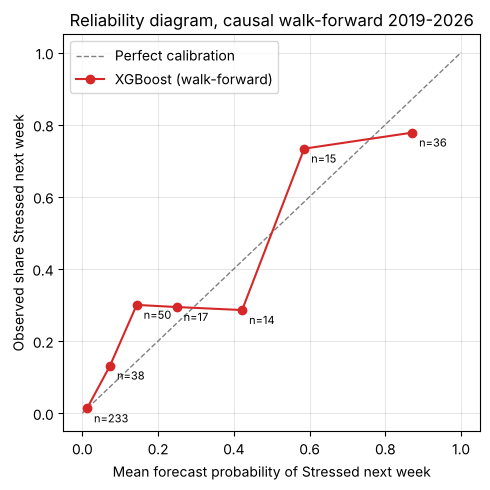

In [ ]:
#  6.9d Calibration of the walk-forward XGBoost probabilities (diagnosis only) 
p_c = wfc_prob.loc[wc]
edges = [0, 0.05, 0.10, 0.20, 0.35, 0.50, 0.70, 1.0]
rel = pd.DataFrame({"p": p_c, "y": nxt_c, "bin": pd.cut(p_c, edges, include_lowest=True)})
rel_tbl = rel.groupby("bin", observed=True).agg(weeks=("y", "size"), mean_forecast=("p", "mean"),
                                                 observed_freq=("y", "mean"))
print("(1) Reliability: mean forecast vs observed share of Stressed next weeks, by forecast bin")
print(rel_tbl.round(3).to_string())

# Murphy decomposition: Brier = reliability - resolution + uncertainty (computed on the bins above)
N, obar = len(rel), rel["y"].mean()
g = rel.groupby("bin", observed=True)
REL = (g.size() * (g["p"].mean() - g["y"].mean()) ** 2).sum() / N
RES = (g.size() * (g["y"].mean() - obar) ** 2).sum() / N
UNC = obar * (1 - obar)
print(f"\n(2) Brier {brier_score_loss(nxt_c, p_c):.4f} = reliability {REL:.4f} (lower is better) "
      f"- resolution {RES:.4f} (higher is better) + uncertainty {UNC:.4f}")

# What did XGBoost say just before each regime change?
thr_c = wfc_thr.loc[wc]
groups = {"Trending -> Trending": (now_c == 0) & (nxt_c == 0), "Trending -> Stressed (entry)": (now_c == 0) & (nxt_c == 1),
          "Stressed -> Trending (exit)": (now_c == 1) & (nxt_c == 0), "Stressed -> Stressed": (now_c == 1) & (nxt_c == 1)}
rows_g = []
for name, m in groups.items():
    rows_g.append({"transition": name, "weeks": int(m.sum()), "median prob.": p_c[m].median(),
                   "max prob.": p_c[m].max(), "share above threshold": (p_c[m] >= thr_c[m]).mean()})
print("\n(3) XGBoost probability of Stressed next week, by what actually happened:")
print(pd.DataFrame(rows_g).set_index("transition").round(3).to_string())

# Among currently Trending weeks: does a higher probability mean a higher entry rate? (quintiles of probability)
tw = now_c == 0
q = pd.qcut(p_c[tw].rank(method="first"), 5, labels=["Q1 low", "Q2", "Q3", "Q4", "Q5 high"])
lift = pd.DataFrame({"p": p_c[tw], "entry": nxt_c[tw], "q": q}).groupby("q", observed=True).agg(
    weeks=("entry", "size"), mean_prob=("p", "mean"), entries=("entry", "sum"), entry_rate=("entry", "mean"))
print(f"\n(4) Currently Trending weeks by XGBoost probability quintile (base entry rate {nxt_c[tw].mean():.1%}):")
print(lift.round(3).to_string())

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=1, label="Perfect calibration")
ax.plot(rel_tbl["mean_forecast"], rel_tbl["observed_freq"], marker="o", color="tab:red", label="XGBoost (walk-forward)")
for _, rw in rel_tbl.iterrows():
    ax.annotate(f"n={int(rw.weeks)}", (rw.mean_forecast, rw.observed_freq), textcoords="offset points", xytext=(5, -10), fontsize=8)
ax.set_xlabel("Mean forecast probability of Stressed next week"); ax.set_ylabel("Observed share Stressed next week")
ax.set_title("Reliability diagram, causal walk-forward 2019-2026"); ax.legend(loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("results/figures/calibration_walkforward.png", dpi=100); plt.show()
rel_tbl.to_csv("results/walkforward_calibration.csv"); lift.to_csv("results/walkforward_entry_lift.csv")

### 6.10 Rule based aggressive basket

In [ ]:
#  Alternative aggressive sleeve chosen by a mechanical rule (no hindsight on returns) 
ETFS = ["XLK", "XLY", "XLF", "XLI", "XLE", "XLB", "XLV", "XLP", "XLU"]
px = snap_close[ETFS].dropna(how="all")                               # from the data snapshot
etf_ret = px.pct_change().dropna()
spy_d = simple_returns[CORE_TICKER]
etf_tr = etf_ret[etf_ret.index <= train_idx[-1]]                      # training window only
betas = etf_tr.apply(lambda s: s.cov(spy_d.reindex(s.index)) / spy_d.reindex(s.index).var())
ALT = list(betas.sort_values(ascending=False).index[:4])
print("Training-window betas:", betas.sort_values(ascending=False).round(2).to_dict())
print("Alternative aggressive basket (top-4 beta):", ALT)

alt_daily = etf_ret[ALT].mean(axis=1)                                 # equal-weighted, same convention as before
alt_wk = ((1 + alt_daily).resample("W-FRI").prod() - 1).loc[:END_DATE]
wk_next_alt = wk_next.copy()
wk_next_alt["Aggressive sleeve"] = alt_wk.shift(-1).reindex(wk_next.index)

# thresholds recomputed from training payoffs of the NEW sleeve, year by year (causal)
d_alt = d.copy(); d_alt["Aggressive"] = wk_next_alt["Aggressive sleeve"].reindex(d.index)
thr_alt = pd.Series(np.nan, index=all_idx)
for y in range(2019, 2027):
    tr_y = all_idx[all_idx < f"{y}-01-01"][:-1]
    te_y = all_idx[(all_idx >= f"{y}-01-01") & (all_idx < f"{y+1}-01-01")]
    g = d_alt.loc[tr_y]
    gt = (g.loc[g.next_regime == 0, "Aggressive"] - g.loc[g.next_regime == 0, "Defensive"]).mean()
    gs = (g.loc[g.next_regime == 1, "Defensive"] - g.loc[g.next_regime == 1, "Aggressive"]).mean()
    thr_alt.loc[te_y] = gt / (gt + gs)
print("Thresholds by year:", thr_alt.groupby(thr_alt.index.year).first().dropna().round(2).to_dict())

#  Walk-forward comparison with the alternative sleeve (drift + 10-pt rebalance band, base costs) 
r_alt = wk_next_alt.loc[widx]
sigs_alt = {
    "XGBoost walk-forward":   (wf_prob.loc[widx] >= thr_alt.loc[widx]).astype(float),
    "Rule: SPY below 40w MA": (data.loc[widx, "dist_ma40w"] < 0).astype(float),
}
rows_a, rets_a = [], {}
for name, s in sigs_alt.items():
    ret, to = bt(widx, s, r_alt, COST_BPS)
    rets_a[name] = ret
    m = metrics(ret); m["Switches"] = int(s.diff().abs().fillna(0).sum()); m["Turnover (ann., one-way)"] = ann_turnover(to)
    rows_a.append({"strategy": name, **m, "% defensive": s.mean()})
for name, ret in {"Static 50% SPY + 50% Aggr.": static_ret(widx, r_alt, 0.5, 0.5, 0.0),
                  "Static 50/25/25 blend":      static_ret(widx, r_alt, 0.5, 0.25, 0.25),
                  "SPY buy-and-hold":           static_ret(widx, r_alt, 1.0, 0.0, 0.0)}.items():
    rets_a[name] = ret
    m = metrics(ret); m["Switches"] = 0
    rows_a.append({"strategy": name, **m, "% defensive": np.nan})
alt_tbl = pd.DataFrame(rows_a).set_index("strategy").round(3)
print(f"\nWalk-forward {widx.min().year}-{widx.max().year} with the rule-based aggressive basket {ALT} (cost {COST_BPS} bps):")
print(alt_tbl.to_string())

for ref in ["Rule: SPY below 40w MA", "Static 50/25/25 blend", "Static 50% SPY + 50% Aggr."]:
    diff = rets_a["XGBoost walk-forward"] - rets_a[ref]
    lo, hi = block_boot_ci(diff)
    print(f"XGBoost minus {ref:28s}: {diff.mean()*52:+.3f} per year, 95% CI [{lo:+.3f}, {hi:+.3f}]")
alt_tbl.to_csv("results/walkforward_alt_basket.csv")

Training-window betas: {'XLK': 1.21, 'XLE': 1.1, 'XLF': 1.09, 'XLY': 1.07, 'XLB': 1.01, 'XLI': 1.0, 'XLV': 0.8, 'XLU': 0.64, 'XLP': 0.63}
Alternative aggressive basket (top-4 beta): ['XLK', 'XLE', 'XLF', 'XLY']
Thresholds by year: {2019: 0.15, 2020: 0.15, 2021: 0.17, 2022: 0.17, 2023: 0.28, 2024: 0.27, 2025: 0.26, 2026: 0.23}

Walk-forward 2019-2026 with the rule-based aggressive basket ['XLK', 'XLE', 'XLF', 'XLY'] (cost 5 bps):
                            Ann. return  Ann. vol  Sharpe  Max drawdown  Switches  Turnover (ann., one-way)  % defensive
strategy                                                                                                                
XGBoost walk-forward              0.149     0.155   0.794        -0.291        49                     2.871        0.194
Rule: SPY below 40w MA            0.166     0.154   0.894        -0.241        19                     1.201        0.191
Static 50% SPY + 50% Aggr.        0.177     0.191   0.804        -0.354         0  

XGBoost minus Rule: SPY below 40w MA      : -0.014 per year, 95% CI [-0.041, +0.014]


XGBoost minus Static 50/25/25 blend       : -0.004 per year, 95% CI [-0.037, +0.031]


XGBoost minus Static 50% SPY + 50% Aggr.  : -0.030 per year, 95% CI [-0.074, +0.025]


In [ ]:
#  Sector-ETF sleeve with causal labels: top-4 beta ETFs re-selected each January from earlier data only 
alt_next = pd.Series(np.nan, index=wk_next.index)
thr_c_alt = pd.Series(np.nan, index=all_idx)
picks = {}
for y in range(2019, 2027):
    hist = etf_ret[etf_ret.index < f"{y}-01-01"]
    spy_h = spy_d.reindex(hist.index)
    b = hist.apply(lambda s: s.cov(spy_h) / spy_h.var())
    top = list(b.sort_values(ascending=False).index[:4]); picks[y] = top
    basket_next = ((1 + etf_ret[top].mean(axis=1)).resample("W-FRI").prod() - 1).shift(-1)  # this basket's next-week return
    yi = wk_next.index[(wk_next.index >= f"{y}-01-01") & (wk_next.index < f"{y+1}-01-01")]
    alt_next.loc[yi] = basket_next.reindex(yi).values
    # break-even threshold: this year's basket vs the defensive sleeve, on vintage-y labels before January y
    nr = vint_nr[y]
    agg, dfn = basket_next.reindex(nr.index), wk_next.loc[nr.index, "Defensive sleeve"]
    gt = (agg[nr == 0] - dfn[nr == 0]).mean(); gs = (dfn[nr == 1] - agg[nr == 1]).mean()
    thr_c_alt.loc[all_idx[(all_idx >= f"{y}-01-01") & (all_idx < f"{y+1}-01-01")]] = (
        gt / (gt + gs) if (gt > 0 and gs > 0) else 0.5)      # same fallback as above
print("Baskets by year:", picks)
print("Thresholds by year:", thr_c_alt.groupby(thr_c_alt.index.year).first().dropna().round(2).to_dict())

r_ca = wk_next.loc[wc].copy(); r_ca["Aggressive sleeve"] = alt_next.loc[wc]
sigs_ca = {"XGBoost (causal labels)":     (wfc_prob.loc[wc] >= thr_c_alt.loc[wc]).astype(float),
           "Persistence (causal labels)": wfc_now.loc[wc].astype(float),
           "Rule: SPY below 40w MA":      (data.loc[wc, "dist_ma40w"] < 0).astype(float)}
rows_ca, rets_ca = [], {}
for name, s in sigs_ca.items():
    ret, to = bt(wc, s, r_ca, COST_BPS)
    rets_ca[name] = ret
    m = metrics(ret); m["Switches"] = int(s.diff().abs().fillna(0).sum()); m["Turnover (ann., one-way)"] = ann_turnover(to)
    rows_ca.append({"strategy": name, **m, "% defensive": s.mean()})
for name, (c_, a_, d_) in {"Static 50% SPY + 50% Aggr.": (0.5, 0.5, 0.0),
                           "Static 50/25/25 blend":      (0.5, 0.25, 0.25),
                           "SPY buy-and-hold":           (1.0, 0.0, 0.0)}.items():
    ret, to, _ = simulate(wc, pd.DataFrame({"core": c_, "aggr": a_, "def": d_}, index=wc), r_ca, COST_BPS)
    rets_ca[name] = ret
    m = metrics(ret); m["Switches"] = 0; m["Turnover (ann., one-way)"] = ann_turnover(to)
    rows_ca.append({"strategy": name, **m, "% defensive": np.nan})
alt_c_tbl = pd.DataFrame(rows_ca).set_index("strategy").round(3)
print(f"\nWalk-forward with causal labels and the yearly re-selected ETF sleeve (cost {COST_BPS} bps):")
print(alt_c_tbl.to_string())
for ref in ["Rule: SPY below 40w MA", "Static 50/25/25 blend"]:
    diff = rets_ca["XGBoost (causal labels)"] - rets_ca[ref]
    lo, hi = block_boot_ci(diff)
    print(f"XGBoost (causal) minus {ref:24s}: {diff.mean()*52:+.3f} per year, 95% CI [{lo:+.3f}, {hi:+.3f}]")
alt_c_tbl.to_csv("results/walkforward_causal_alt_basket.csv")

Baskets by year: {2019: ['XLK', 'XLE', 'XLF', 'XLB'], 2020: ['XLK', 'XLE', 'XLF', 'XLB'], 2021: ['XLE', 'XLK', 'XLF', 'XLI'], 2022: ['XLE', 'XLK', 'XLF', 'XLI'], 2023: ['XLK', 'XLE', 'XLF', 'XLY'], 2024: ['XLK', 'XLE', 'XLF', 'XLY'], 2025: ['XLK', 'XLY', 'XLF', 'XLE'], 2026: ['XLK', 'XLY', 'XLF', 'XLE']}
Thresholds by year: {2019: 0.18, 2020: 0.3, 2021: 0.14, 2022: 0.16, 2023: 0.32, 2024: 0.26, 2025: 0.25, 2026: 0.22}

Walk-forward with causal labels and the yearly re-selected ETF sleeve (cost 5 bps):
                             Ann. return  Ann. vol  Sharpe  Max drawdown  Switches  Turnover (ann., one-way)  % defensive
strategy                                                                                                                 
XGBoost (causal labels)            0.141     0.152   0.762        -0.277        55                     3.393        0.208
Persistence (causal labels)        0.166     0.151   0.908        -0.253        37                     2.299        0.179
Rule:

XGBoost (causal) minus Rule: SPY below 40w MA  : -0.021 per year, 95% CI [-0.047, +0.004]


XGBoost (causal) minus Static 50/25/25 blend   : -0.014 per year, 95% CI [-0.047, +0.023]


### 6.11 Does the deep component matter? Autoencoder seeds and simpler labellers

**Why.** The title claims a deep-learning contribution, but the labelling stage has never been compared with simpler
ways of getting two regimes, and the autoencoder was trained with a single seed. **What.** The same causal
walk-forward (labeller, XGBoost and threshold refit each January) is run with: the autoencoder under five seeds;
k-means on the eight standardised features (no autoencoder); k-means on the first three principal components (a
linear 3-factor compression, the closest non-deep analogue); and a two-state Gaussian hidden Markov model, labelled
with *filtered* probabilities (each week uses only data up to that week). Every labeller names its clusters with the
same stress score. **How.** For each labeller we report agreement with the main labels (adjusted Rand index), the
share of Stressed weeks and episode coverage, forecast skill, and portfolio results including persistence and the
oracle, so the value of the labels is separated from the value of the forecast.

*Note:* k-means on the eight features and k-means on the first three principal components give identical partitions in every vintage: the three components keep about 84% of the variance, including the direction that separates the two clusters.


In [ ]:
#  6.11 Labelling-stage robustness: autoencoder seeds and simpler labellers (causal walk-forward) 
import sys
from sklearn.decomposition import PCA
try:
    from hmmlearn.hmm import GaussianHMM
except ImportError:                                   # not preinstalled in Colab
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "hmmlearn"], check=True)
    from hmmlearn.hmm import GaussianHMM
from scipy.special import logsumexp
from scipy.stats import multivariate_normal
import logging; logging.getLogger("hmmlearn").setLevel(logging.ERROR)

def stressed_id(zf, raw_fit):
    """Cluster with the highest stress score (same score as section 5)."""
    zm = zf.groupby(raw_fit).mean()
    return (zm["rvol_13w"] + zm["rvol_1w"] - zm["ret_13w"] - zm["dist_ma40w"] - zm["drawdown_52w"]).idxmax()

def hmm_filtered(hmm, Z):
    """Forward-filtered state probabilities: P(state at t | data up to t). No smoothing, so no look-ahead."""
    logB = np.column_stack([multivariate_normal(hmm.means_[k], np.atleast_2d(hmm.covars_[k]) if hmm.covars_[k].ndim == 2
                                                else np.diag(hmm.covars_[k])).logpdf(Z) for k in range(hmm.n_components)])
    logA, la = np.log(hmm.transmat_), np.log(hmm.startprob_) + logB[0]
    out = np.empty_like(logB); out[0] = la - logsumexp(la)
    for t_ in range(1, len(Z)):
        la = logsumexp(out[t_ - 1][:, None] + logA, axis=0) + logB[t_]
        out[t_] = la - logsumexp(la)
    return np.exp(out)

def make_labeller(method, fit_idx, seed=SEED):
    """Return a function idx -> 0/1 labels, fitted on fit_idx only."""
    if method == "autoencoder":
        return fit_labeller(fit_idx, seed=seed)[0]
    sc = StandardScaler().fit(X.loc[fit_idx])
    zf = pd.DataFrame(sc.transform(X.loc[fit_idx]), index=fit_idx, columns=REGIME_FEATURES)
    if method == "kmeans_raw":
        km_ = KMeans(2, n_init=20, random_state=seed).fit(zf.values)
        s_ = stressed_id(zf, km_.labels_)
        return lambda idx: pd.Series((km_.predict(sc.transform(X.loc[idx])) == s_).astype(int), index=idx)
    if method == "kmeans_pca":
        pca = PCA(n_components=N_LATENT, random_state=seed).fit(zf.values)
        km_ = KMeans(2, n_init=20, random_state=seed).fit(pca.transform(zf.values))
        s_ = stressed_id(zf, km_.labels_)
        return lambda idx: pd.Series((km_.predict(pca.transform(sc.transform(X.loc[idx]))) == s_).astype(int), index=idx)
    if method == "hmm":
        hmm = GaussianHMM(n_components=2, covariance_type="diag", n_iter=500, random_state=seed).fit(zf.values)
        s_ = stressed_id(zf, hmm_filtered(hmm, zf.values).argmax(1))
        return lambda idx: pd.Series((hmm_filtered(hmm, sc.transform(X.loc[idx])).argmax(1) == s_).astype(int), index=idx)
    raise ValueError(method)

def run_causal_wf(method, seed=SEED):
    """Same procedure as section 6.9b for any labeller. Labels are produced by running the vintage on all weeks
    from December 2015 in order (the HMM filter needs the history), and only weeks of year y are used."""
    out = {k: pd.Series(np.nan, index=all_idx) for k in ["prob", "thr", "now", "next"]}
    for y in range(2019, 2027):
        fit_y = X.index[X.index < f"{y}-01-01"]
        lab_y = make_labeller(method, fit_y, seed)(X.index)
        D = build_dataset(lab_y)
        tr_y = D.index[D.index < f"{y}-01-01"][:-1]
        te_y = D.index[(D.index >= f"{y}-01-01") & (D.index < f"{y+1}-01-01")]
        mdl = XGBClassifier(**XGB_PARAMS).fit(D.loc[tr_y, STATE_COLS], D.loc[tr_y, "next_regime"])
        out["prob"].loc[te_y] = mdl.predict_proba(D.loc[te_y, STATE_COLS])[:, 1]
        out["now"].loc[te_y] = D.loc[te_y, "regime_now"]; out["next"].loc[te_y] = D.loc[te_y, "next_regime"]
        nr, pay = D.loc[tr_y, "next_regime"], wk_next.loc[tr_y]
        gt = (pay.loc[nr == 0, "Aggressive sleeve"] - pay.loc[nr == 0, "Defensive sleeve"]).mean()
        gs = (pay.loc[nr == 1, "Defensive sleeve"] - pay.loc[nr == 1, "Aggressive sleeve"]).mean()
        out["thr"].loc[te_y] = gt / (gt + gs) if (gt > 0 and gs > 0) else 0.5
    return {k: v.loc[wc] for k, v in out.items()}

RUNS = [("Autoencoder, seed 42 (main)", "autoencoder", 42)] + \
       [(f"Autoencoder, seed {s_}", "autoencoder", s_) for s_ in (1, 2, 3, 4)] + \
       [("k-means on 8 features", "kmeans_raw", SEED), ("k-means on 3 PCA factors", "kmeans_pca", SEED),
        ("2-state Gaussian HMM (filtered)", "hmm", SEED)]
wf_runs = {name: run_causal_wf(method, seed) for name, method, seed in RUNS}
main = wf_runs["Autoencoder, seed 42 (main)"]
assert np.allclose(main["prob"], wfc_prob.loc[wc]), "main run should reproduce section 6.9b"

eps = {"COVID crash": ("2020-02-15", "2020-04-30"), "2022 bear market": ("2022-01-01", "2022-10-31")}
r_wf = wk_next.loc[wc]
rows_l, rows_p = [], []
for name, o in wf_runs.items():
    now_, nxt_, sx_ = o["now"].astype(int), o["next"].astype(int), (o["prob"] >= o["thr"]).astype(float)
    tw_ = now_ == 0
    rows_l.append({"labeller": name,
                   "ARI vs main": adjusted_rand_score(main["now"], now_),
                   "% Stressed": now_.mean(),
                   **{f"{e} covered": now_.loc[a:b].mean() for e, (a, b) in eps.items()},
                   "Exp. Stressed spell (wks)": 1 / max(1e-9, ((now_ == 1) & (nxt_ == 0)).sum() / max(1, (now_ == 1).sum())),
                   "Transitions": int((now_ != nxt_).sum()),
                   "AUC XGBoost": roc_auc_score(nxt_, o["prob"]), "AUC persistence": roc_auc_score(nxt_, now_),
                   "AUC entry (now Trending)": roc_auc_score(nxt_[tw_], o["prob"][tw_]) if nxt_[tw_].nunique() > 1 else np.nan})
    rets_ = {}
    for sname, s in {"XGBoost": sx_, "Persistence": now_.astype(float), "Oracle": nxt_.astype(float)}.items():
        ret, to = bt(wc, s, r_wf, COST_BPS); rets_[sname] = ret
        m = metrics(ret)
        rows_p.append({"labeller": name, "signal": sname, "Sharpe": m["Sharpe"], "Ann. return": m["Ann. return"],
                       "Max drawdown": m["Max drawdown"], "Turnover (ann., one-way)": ann_turnover(to)})
    lo, hi = block_boot_ci(rets_["XGBoost"] - rets_c["Rule: SPY below 40w MA"])
    rows_p.append({"labeller": name, "signal": "XGBoost minus 40w rule (ann. return)",
                   "Ann. return": (rets_["XGBoost"] - rets_c["Rule: SPY below 40w MA"]).mean() * 52,
                   "Sharpe": np.nan, "Max drawdown": np.nan, "Turnover (ann., one-way)": np.nan, "CI": f"[{lo:+.3f}, {hi:+.3f}]"})

lab_tbl = pd.DataFrame(rows_l).set_index("labeller").round(3)
port_tbl = pd.DataFrame(rows_p).set_index(["labeller", "signal"])
print("(1) Labels and forecast skill by labeller (causal walk-forward, 2019-2026):")
print(lab_tbl.to_string())
print(f"\n(2) Portfolio results by labeller (40-week rule for reference: Sharpe "
      f"{wfc_tbl.loc['Rule: SPY below 40w MA', 'Sharpe']:.3f}, max drawdown {wfc_tbl.loc['Rule: SPY below 40w MA', 'Max drawdown']:.3f}):")
print(port_tbl.round(3).fillna("").to_string())

ae = [n for n in wf_runs if n.startswith("Autoencoder")]
sh = port_tbl.xs("XGBoost", level="signal").loc[ae, "Sharpe"]
print(f"\nAutoencoder seeds: XGBoost Sharpe mean {sh.mean():.3f}, range {sh.min():.3f} to {sh.max():.3f}; "
      f"pairwise label ARI between seeds: min "
      f"{min(adjusted_rand_score(wf_runs[a]['now'], wf_runs[b]['now']) for a in ae for b in ae if a < b):.3f}")
lab_tbl.to_csv("results/ablation_labels.csv"); port_tbl.round(4).to_csv("results/ablation_portfolio.csv")

(1) Labels and forecast skill by labeller (causal walk-forward, 2019-2026):
                                 ARI vs main  % Stressed  COVID crash covered  2022 bear market covered  Exp. Stressed spell (wks)  Transitions  AUC XGBoost  AUC persistence  AUC entry (now Trending)
labeller                                                                                                                                                                                               
Autoencoder, seed 42 (main)            1.000       0.179                  0.9                     0.605                      3.789           37        0.908            0.845                     0.833
Autoencoder, seed 1                    0.405       0.087                  0.8                     0.116                      1.842           37        0.874            0.710                     0.856
Autoencoder, seed 2                    0.734       0.161                  0.8                     0.535                     

### 6.12 A pre-specified ensemble: majority vote

**Why.** XGBoost, the 40-week rule and the HMM look at the market differently, so combining them might fix the
weeks where each one is wrong. **What.** One rule, fixed *before* looking at its result and counted as one more trial:
hold the defensive sleeve when at least two of three signals say Stressed: (1) XGBoost at the break-even threshold
(main labels), (2) SPY below its 40-week average, (3) the HMM's filtered current state is Stressed. **How.** Same
causal walk-forward, simulator, costs and band. No other combination is tried, to avoid adding selection bias.

In [ ]:
#  6.12 Pre-specified majority vote of XGBoost, the 40-week rule and the HMM (causal walk-forward) 
v_x = (main["prob"] >= main["thr"]).astype(int)
v_m = (data.loc[wc, "dist_ma40w"] < 0).astype(int)
v_h = wf_runs["2-state Gaussian HMM (filtered)"]["now"].astype(int)
vote = ((v_x + v_m + v_h) >= 2).astype(float)

rows_v, rets_v = [], {}
for name, s in {"Majority vote (XGBoost, 40w rule, HMM)": vote, "XGBoost (causal labels)": v_x.astype(float),
                "Rule: SPY below 40w MA": v_m.astype(float), "HMM state (filtered)": v_h.astype(float)}.items():
    ret, to = bt(wc, s, r_wf, COST_BPS); rets_v[name] = ret
    m = metrics(ret); m.pop("Switches")
    rows_v.append({"strategy": name, **m, "Turnover (ann., one-way)": ann_turnover(to), "% defensive": s.mean()})
vote_tbl = pd.DataFrame(rows_v).set_index("strategy").round(3)
print(f"Majority vote vs its components (causal walk-forward, cost {COST_BPS} bps):")
print(vote_tbl.to_string())
print(f"\nAgreement: all three agree in {((v_x == v_m) & (v_m == v_h)).mean():.0%} of weeks; "
      f"the vote differs from the 40-week rule in {int((vote != v_m).sum())} weeks")
for ref in ["Rule: SPY below 40w MA", "XGBoost (causal labels)"]:
    diff = rets_v["Majority vote (XGBoost, 40w rule, HMM)"] - rets_v[ref]
    lo, hi = block_boot_ci(diff)
    print(f"Vote minus {ref:24s}: {diff.mean()*52:+.3f} per year, 95% CI [{lo:+.3f}, {hi:+.3f}]")
vote_tbl.to_csv("results/walkforward_vote.csv")

Majority vote vs its components (causal walk-forward, cost 5 bps):
                                        Ann. return  Ann. vol  Sharpe  Max drawdown  Turnover (ann., one-way)  % defensive
strategy                                                                                                                  
Majority vote (XGBoost, 40w rule, HMM)        0.227     0.178   1.086        -0.317                     2.119        0.221
XGBoost (causal labels)                       0.214     0.186   0.990        -0.421                     2.643        0.161
Rule: SPY below 40w MA                        0.255     0.182   1.188        -0.313                     1.276        0.191
HMM state (filtered)                          0.160     0.157   0.847        -0.303                     2.170        0.424

Agreement: all three agree in 71% of weeks; the vote differs from the 40-week rule in 12 weeks


Vote minus Rule: SPY below 40w MA  : -0.023 per year, 95% CI [-0.046, -0.004]


Vote minus XGBoost (causal labels) : +0.010 per year, 95% CI [-0.016, +0.036]


### 6.13 Separate entry and exit models, chosen each January on earlier data only

**Why.** Sections 6.9c and 6.9d show that entering and leaving the Stressed regime are different problems. Entries
are rare (about 5% of Trending weeks) and XGBoost ranks them well but cannot act on them; exits are common (about 26%
of Stressed weeks) and XGBoost recognises them too late, while the 40-week rule exits faster. One model for both may
be the wrong design.
**What.** Two models: an *entry* model fitted on currently Trending weeks and an *exit* model fitted on currently
Stressed weeks. Both forecast P(Stressed next week), so they combine into one probability and use the same
break-even threshold, simulator and costs as before. Four candidates per side, fixed in advance: a constant base rate
(pure persistence), logistic regression, XGBoost (same settings as before), and the 40-week rule turned into a
probability (the training-period frequency of Stressed next week when SPY is below / above its 40-week average).
Inputs: the eight market-state features plus the share of Stressed weeks in the last four.
**How.** The choice is made *inside* the walk-forward, so it never sees the year it trades: each January, every
candidate is scored by log-loss in an inner walk-forward over the earlier years only (fit on weeks before year k,
forecast year k, for k = 2017 up to the year before the origin), the best candidate per side is refitted on all
earlier weeks, and it forecasts the coming year. Choosing by log-loss over all weeks in a state uses far more
information than counting the 18 to 19 transitions. Because the selection is part of the procedure, the traded
strategy is a single new trial.

In [ ]:
#  6.13 Entry and exit models, one candidate per side chosen each January by inner walk-forward log-loss 
from sklearn.metrics import log_loss
SIDE_COLS = REGIME_FEATURES + ["stress_4w"]
CANDS = ["Base rate", "Logistic", "XGBoost", "40w rule"]
SIDES = {0: "entry (now Trending)", 1: "exit (now Stressed)"}
EPS = 1e-3

def cand_fit(name, Dtr):
    """Fit one candidate on the weeks in Dtr (all in the same current regime); returns Dte -> P(Stressed next)."""
    y_ = Dtr["next_regime"].astype(int)
    base = float(np.clip(y_.mean(), EPS, 1 - EPS))
    if name == "Base rate" or y_.nunique() < 2:
        return lambda Dte: np.full(len(Dte), base)
    if name == "Logistic":
        sc_ = StandardScaler().fit(Dtr[SIDE_COLS])
        m_ = LogisticRegression(C=1.0, max_iter=2000).fit(sc_.transform(Dtr[SIDE_COLS]), y_)
        return lambda Dte: m_.predict_proba(sc_.transform(Dte[SIDE_COLS]))[:, 1]
    if name == "XGBoost":
        m_ = XGBClassifier(**XGB_PARAMS).fit(Dtr[SIDE_COLS], y_)
        return lambda Dte: m_.predict_proba(Dte[SIDE_COLS])[:, 1]
    if name == "40w rule":
        below = Dtr["dist_ma40w"] < 0
        p1 = y_[below].mean() if below.sum() else base
        p0 = y_[~below].mean() if (~below).sum() else base
        return lambda Dte: np.where(Dte["dist_ma40w"] < 0, p1, p0)
    raise ValueError(name)

def inner_scores(D_in, origin, state):
    """Inner walk-forward on weeks before the origin only: log-loss of each candidate, pooled over years."""
    preds, ys = {c: [] for c in CANDS}, []
    for k in range(2017, origin):
        before = D_in.index[D_in.index < f"{k}-01-01"][:-1]   # drop last week: its target is in year k
        a = D_in.loc[before]; a = a[a["regime_now"] == state]
        b = D_in[(D_in.index >= f"{k}-01-01") & (D_in.index < f"{k+1}-01-01") & (D_in["regime_now"] == state)]
        if len(b) == 0 or len(a) < 10:
            continue
        ys.append(b["next_regime"].astype(int).values)
        for c in CANDS:
            preds[c].append(cand_fit(c, a)(b))
    if not ys:
        return {c: np.nan for c in CANDS}
    y_all = np.concatenate(ys)
    return {c: log_loss(y_all, np.clip(np.concatenate(preds[c]), EPS, 1 - EPS), labels=[0, 1]) for c in CANDS}

tm_prob = pd.Series(np.nan, index=all_idx)
every = {(s, c): pd.Series(np.nan, index=all_idx) for s in SIDES for c in CANDS}   # diagnostics only
choice_rows = []
for y in range(2019, 2027):
    D = vint_D[y]
    tr_y = D.index[D.index < f"{y}-01-01"][:-1]
    te_y = D.index[(D.index >= f"{y}-01-01") & (D.index < f"{y+1}-01-01")]
    D_in, D_te = D.loc[tr_y], D.loc[te_y]
    row = {"origin": y}
    for s, side in SIDES.items():
        sc_in = inner_scores(D_in, y, s)
        best = min((c for c in CANDS if not np.isnan(sc_in[c])), key=sc_in.get, default="Base rate")
        fit_on, go = D_in[D_in["regime_now"] == s], D_te[D_te["regime_now"] == s]
        if len(go):
            for c in CANDS:
                every[(s, c)].loc[go.index] = cand_fit(c, fit_on)(go)
            tm_prob.loc[go.index] = every[(s, best)].loc[go.index]
        row[f"{side.split()[0]} model"] = best
        row.update({f"{side.split()[0]} LL {c}": sc_in[c] for c in CANDS})
    choice_rows.append(row)
choice_tbl = pd.DataFrame(choice_rows).set_index("origin")
print("(1) Candidate chosen each January (inner walk-forward log-loss on earlier years; lower is better):")
print(choice_tbl.round(3).to_string())

# (2) How each candidate did out of sample on each side (diagnostic only: NOT used for the choice)
rows_s = []
for s, side in SIDES.items():
    m = (now_c == s).values
    yv = nxt_c[m]
    for c in CANDS + ["Chosen each year", "Single XGBoost (6.9b)"]:
        p = (tm_prob if c == "Chosen each year" else wfc_prob if c.startswith("Single") else every[(s, c)]).loc[wc][m]
        rows_s.append({"side": side, "model": c, "weeks": int(m.sum()), "events": int((yv != s).sum()),
                       "log-loss": log_loss(yv, np.clip(p, EPS, 1 - EPS), labels=[0, 1]),
                       "Brier": brier_score_loss(yv, p), "AUC": roc_auc_score(yv, p) if yv.nunique() > 1 else np.nan,
                       "events acted on": int(((p >= wfc_thr.loc[wc][m]) != bool(s))[yv != s].sum())})
side_tbl = pd.DataFrame(rows_s).set_index(["side", "model"]).round(3)
print("\n(2) Out-of-sample quality by side, 2019-2026 (events = entries or exits; 'acted on' = signal switched in time):")
print(side_tbl.to_string())

# (3) Portfolio
s_tm = (tm_prob.loc[wc] >= wfc_thr.loc[wc]).astype(float)
rows_t, rets_t = [], {}
for name, s in {"Entry/exit models (chosen each year)": s_tm, "XGBoost (causal labels)": s_x.astype(float),
                "Persistence (causal labels)": now_c.astype(float), "Rule: SPY below 40w MA": s_m.astype(float)}.items():
    ret, to = bt(wc, s, r_wf, COST_BPS); rets_t[name] = ret
    m_ = metrics(ret); m_.pop("Switches")
    rows_t.append({"strategy": name, **m_, "Turnover (ann., one-way)": ann_turnover(to), "% defensive": s.mean()})
tm_tbl = pd.DataFrame(rows_t).set_index("strategy").round(3)
print(f"\n(3) Portfolio, causal walk-forward 2019-2026 (cost {COST_BPS} bps, drift + band):")
print(tm_tbl.to_string())
rc_t = pd.DataFrame(rets_t)
print("\nCalendar-year returns:")
print(rc_t.groupby(rc_t.index.year).apply(lambda x: (1 + x).prod() - 1).round(3).T.to_string())
for ref in ["Rule: SPY below 40w MA", "Persistence (causal labels)", "XGBoost (causal labels)"]:
    diff = rets_t["Entry/exit models (chosen each year)"] - rets_t[ref]
    lo, hi = block_boot_ci(diff)
    print(f"Entry/exit minus {ref:28s}: {diff.mean()*52:+.3f} per year, 95% CI [{lo:+.3f}, {hi:+.3f}]")
choice_tbl.round(4).to_csv("results/entry_exit_choices.csv"); side_tbl.to_csv("results/entry_exit_sides.csv")
tm_tbl.to_csv("results/entry_exit_portfolio.csv")

(1) Candidate chosen each January (inner walk-forward log-loss on earlier years; lower is better):
       entry model  entry LL Base rate  entry LL Logistic  entry LL XGBoost  entry LL 40w rule exit model  exit LL Base rate  exit LL Logistic  exit LL XGBoost  exit LL 40w rule
origin                                                                                                                                                                           
2019       XGBoost               0.325              0.361             0.324              0.324  Base rate                NaN               NaN              NaN               NaN
2020       XGBoost               0.289              0.257             0.256              0.289    XGBoost              0.692             1.165            0.630             0.651
2021      40w rule               0.324              0.344             0.332              0.322   40w rule              0.669             0.976            0.520             0.390
2022     Ba


(3) Portfolio, causal walk-forward 2019-2026 (cost 5 bps, drift + band):
                                      Ann. return  Ann. vol  Sharpe  Max drawdown  Turnover (ann., one-way)  % defensive
strategy                                                                                                                
Entry/exit models (chosen each year)        0.213     0.186   0.985        -0.413                     2.541        0.164
XGBoost (causal labels)                     0.214     0.186   0.990        -0.421                     2.643        0.161
Persistence (causal labels)                 0.237     0.183   1.104        -0.372                     2.369        0.179
Rule: SPY below 40w MA                      0.255     0.182   1.188        -0.313                     1.276        0.191

Calendar-year returns:
Date                                   2019   2020   2021   2022   2023   2024   2025   2026
Entry/exit models (chosen each year)  0.384  0.307  0.312 -0.356  0.370  0.507  0.2

Entry/exit minus Rule: SPY below 40w MA      : -0.033 per year, 95% CI [-0.070, +0.000]


Entry/exit minus Persistence (causal labels) : -0.019 per year, 95% CI [-0.043, +0.003]


Entry/exit minus XGBoost (causal labels)     : -0.001 per year, 95% CI [-0.023, +0.022]


**Where is the payoff?** The break-even threshold assumes that whenever next week is Stressed, the defensive sleeve
wins by the average training-period margin. The table below splits next week's payoff (defensive minus aggressive
sleeve, % per week) by this week's and next week's regime, over the causal walk-forward.

In [ ]:
#  6.13b Payoff of the defensive sleeve by transition type (diagnostic, causal walk-forward) 
gapd = 100 * (wk_next.loc[wc, "Defensive sleeve"] - wk_next.loc[wc, "Aggressive sleeve"])
dfp = pd.DataFrame({"now": now_c.map(REGIME_NAMES), "next": nxt_c.map(REGIME_NAMES),
                    "SPY below 40w MA": s_m.astype(bool), "gap": gapd})
agg = dict(weeks=("gap", "size"), mean_def_minus_aggr=("gap", "mean"), defensive_wins=("gap", lambda g: (g > 0).mean()))
print("Next-week payoff of holding the defensive instead of the aggressive sleeve (% per week), by transition:")
print(dfp.groupby(["now", "next"]).agg(**agg).round(3).to_string())
print("\nWithin each current regime, split by the 40-week rule:")
print(dfp.groupby(["now", "SPY below 40w MA"]).agg(**agg, share_stressed_next=("next", lambda n: (n == "Stressed").mean())).round(3).to_string())
dfp.groupby(["now", "next"]).agg(**agg).round(4).to_csv("results/payoff_by_transition.csv")

Next-week payoff of holding the defensive instead of the aggressive sleeve (% per week), by transition:
                   weeks  mean_def_minus_aggr  defensive_wins
now      next                                                
Stressed Stressed     53                0.268           0.642
         Trending     19               -4.598           0.105
Trending Stressed     18                3.582           0.833
         Trending    313               -0.706           0.409

Within each current regime, split by the 40-week rule:
                           weeks  mean_def_minus_aggr  defensive_wins  share_stressed_next
now      SPY below 40w MA                                                                 
Stressed False                13               -1.806           0.385                0.462
         True                 59               -0.842           0.525                0.797
Trending False               313               -0.509           0.425                0.038
         True

### 6.14 Defensive sleeve with T-bills (one pre-declared variant)

**Why.** The defensive sleeve (long Treasuries and gold) assumes bonds hedge equity stress. In 2022 stocks and long
Treasuries fell together, and the defensive sleeve lost money in Stressed weeks of the validation and test periods.
**What.** One variant, declared before running: the defensive sleeve becomes TLT, GLD and BIL (1-3 month T-bills)
in equal weights. Nothing else changes. **How.** Same causal labels, XGBoost forecasts and simulator; the break-even
threshold is recomputed each January from the new sleeve's payoffs on earlier weeks. If the strategies improve in
2022 with the same signals, the problem was the hedge, not the forecast.

In [ ]:
#  6.14 Defensive sleeve = TLT, GLD, BIL (equal weight): is 2022 a hedging or a forecasting failure? 
d_tb = snap_close[["TLT", "GLD", "BIL"]].pct_change().reindex(sleeve_returns.index).fillna(0).mean(axis=1)
sleeve_tb = sleeve_returns.copy(); sleeve_tb["Defensive sleeve"] = d_tb
wk_next_tb = ((1 + sleeve_tb).resample("W-FRI").prod() - 1).loc[:END_DATE].shift(-1)

thr_tb = pd.Series(np.nan, index=all_idx)
for y in range(2019, 2027):
    nr = vint_nr[y]; pay = wk_next_tb.loc[nr.index]
    gt = (pay.loc[nr == 0, "Aggressive sleeve"] - pay.loc[nr == 0, "Defensive sleeve"]).mean()
    gs = (pay.loc[nr == 1, "Defensive sleeve"] - pay.loc[nr == 1, "Aggressive sleeve"]).mean()
    thr_tb.loc[all_idx[(all_idx >= f"{y}-01-01") & (all_idx < f"{y+1}-01-01")]] = gt / (gt + gs) if (gt > 0 and gs > 0) else 0.5
print("Thresholds by year:", thr_tb.groupby(thr_tb.index.year).first().dropna().round(2).to_dict())

pay_cmp = pd.DataFrame({"next week": nxt_c.map(REGIME_NAMES),
                        "TLT+GLD": 100 * wk_next.loc[wc, "Defensive sleeve"],
                        "TLT+GLD+BIL": 100 * wk_next_tb.loc[wc, "Defensive sleeve"],
                        "Aggressive": 100 * wk_next.loc[wc, "Aggressive sleeve"]})
print("\nMean weekly return by next week's regime, walk-forward (%):")
print(pay_cmp.groupby("next week").mean().round(3).to_string())
print("2022 only:")
print(pay_cmp.loc["2022"].groupby("next week").mean().round(3).to_string())

r_tb = wk_next_tb.loc[wc]
rows_tb, rets_tb = [], {}
for name, s in {"XGBoost (causal labels)": (wfc_prob.loc[wc] >= thr_tb.loc[wc]).astype(float),
                "Persistence (causal labels)": now_c.astype(float),
                "Rule: SPY below 40w MA": s_m.astype(float)}.items():
    ret, to = bt(wc, s, r_tb, COST_BPS); rets_tb[name] = ret
    m = metrics(ret); m.pop("Switches")
    rows_tb.append({"strategy": name, **m, "Turnover (ann., one-way)": ann_turnover(to), "% defensive": s.mean()})
for name, w_ in {"Static 50/25/25 blend": (0.5, 0.25, 0.25), "Static 50% SPY + 50% Aggr.": (0.5, 0.5, 0.0)}.items():
    ret, to, _ = simulate(wc, pd.DataFrame({"core": w_[0], "aggr": w_[1], "def": w_[2]}, index=wc), r_tb, COST_BPS)
    rets_tb[name] = ret; m = metrics(ret); m.pop("Switches")
    rows_tb.append({"strategy": name, **m, "Turnover (ann., one-way)": ann_turnover(to), "% defensive": np.nan})
tb_tbl = pd.DataFrame(rows_tb).set_index("strategy").round(3)
print(f"\nWalk-forward with the T-bill defensive sleeve (cost {COST_BPS} bps; Sharpe in excess of T-bills):")
print(tb_tbl.to_string())
yr_tb = pd.DataFrame(rets_tb); yr_tb = yr_tb.groupby(yr_tb.index.year).apply(lambda x: (1 + x).prod() - 1)
print("\nCalendar-year returns:"); print(yr_tb.round(3).T.to_string())
diff = rets_tb["XGBoost (causal labels)"] - rets_tb["Rule: SPY below 40w MA"]; lo, hi = block_boot_ci(diff)
print(f"XGBoost minus 40w rule (T-bill sleeve): {diff.mean()*52:+.3f} per year, 95% CI [{lo:+.3f}, {hi:+.3f}]")
tb_tbl.to_csv("results/walkforward_tbill_sleeve.csv")

Thresholds by year: {2019: 0.27, 2020: 0.57, 2021: 0.35, 2022: 0.34, 2023: 0.4, 2024: 0.36, 2025: 0.37, 2026: 0.34}

Mean weekly return by next week's regime, walk-forward (%):
           TLT+GLD  TLT+GLD+BIL  Aggressive
next week                                  
Stressed     0.124        0.096      -0.984
Trending     0.150        0.118       1.079
2022 only:
           TLT+GLD  TLT+GLD+BIL  Aggressive
next week                                  
Stressed    -0.220       -0.134      -1.385
Trending    -0.186       -0.119       0.673



Walk-forward with the T-bill defensive sleeve (cost 5 bps; Sharpe in excess of T-bills):
                             Ann. return  Ann. vol  Sharpe  Max drawdown  Turnover (ann., one-way)  % defensive
strategy                                                                                                       
XGBoost (causal labels)            0.213     0.183   0.997        -0.404                     2.665        0.159
Persistence (causal labels)        0.232     0.181   1.096        -0.356                     2.357        0.179
Rule: SPY below 40w MA             0.253     0.179   1.197        -0.287                     1.270        0.191
Static 50/25/25 blend              0.220     0.176   1.060        -0.320                     0.030          NaN
Static 50% SPY + 50% Aggr.         0.289     0.227   1.113        -0.362                     0.039          NaN

Calendar-year returns:
Date                          2019   2020   2021   2022   2023   2024   2025   2026
XGBoost (causal la

XGBoost minus 40w rule (T-bill sleeve): -0.032 per year, 95% CI [-0.068, -0.001]


### 6.15 Persistent labels: statistical jump model and smoothed forecasts (pre-declared, one trial)

**Why.** The closest published design (Shu, Yu and Mulvey 2024, 2025) also labels regimes without supervision and
forecasts them with XGBoost, and reports positive results. Two differences stand out: their labels come from a
*statistical jump model*, which penalises every regime switch so regimes are persistent (higher signal-to-noise,
at the cost of some delay), and they *smooth* the XGBoost probabilities, which otherwise switch too often.
**What.** The same eight standardised features are clustered into two states by a jump model: minimise the squared
distance of each week to its state centroid plus a penalty lambda for every change of state. With lambda = 0 this is
exactly k-means (section 6.11), so the only new ingredient is persistence. The current week's state is inferred
*online* (a forward pass that uses data up to that week only); the training target is the jump model's fitted
state sequence. XGBoost (same settings and inputs as before) forecasts next week's state; its probability is
exponentially smoothed. **How.** lambda in {0, 10, 30, 100} and the smoothing half-life in {none, 2, 4 weeks} are
chosen each January by the Sharpe ratio of the strategy over the earlier years only (inner walk-forward from
2017), as in the original paper; the break-even threshold is computed as before from the new labels' payoffs.
The whole selection procedure is one trial.

In [ ]:
#  6.15 Statistical jump model labels + smoothed XGBoost, settings chosen by inner walk-forward Sharpe 
from scipy.stats import norm, skew, kurtosis

def lw_sharpe_test(x, y):
    """Ledoit-Wolf (2008) test of equal Sharpe ratios on excess returns, HAC (Newey-West/Bartlett) standard error.
    Returns (annualised Sharpe difference, two-sided p-value)."""
    x, y = np.asarray(x, float), np.asarray(y, float); T_ = len(x)
    mu1, mu2, g1, g2 = x.mean(), y.mean(), (x ** 2).mean(), (y ** 2).mean()
    s1, s2 = g1 - mu1 ** 2, g2 - mu2 ** 2
    grad = np.array([g1 / s1 ** 1.5, -g2 / s2 ** 1.5, -mu1 / (2 * s1 ** 1.5), mu2 / (2 * s2 ** 1.5)])
    V = np.column_stack([x - mu1, y - mu2, x ** 2 - g1, y ** 2 - g2])
    L = int(np.floor(4 * (T_ / 100) ** (2 / 9)))
    Psi = V.T @ V / T_
    for l in range(1, L + 1):
        G = V[l:].T @ V[:-l] / T_; Psi += (1 - l / (L + 1)) * (G + G.T)
    d = mu1 / np.sqrt(s1) - mu2 / np.sqrt(s2)
    return d * np.sqrt(52), 2 * (1 - norm.cdf(abs(d) / np.sqrt(grad @ Psi @ grad / T_)))

JM_LAMBDAS, JM_HALFLIVES = [0, 10, 30, 100], [0, 2, 4]

def jm_dp(L, lam):
    """Optimal state path for costs L (T x K) with a penalty lam per change of state (dynamic programming)."""
    T_, K_ = L.shape; pen = lam * (1 - np.eye(K_))
    V = np.empty((T_, K_)); B = np.zeros((T_, K_), int); V[0] = L[0]
    for t_ in range(1, T_):
        c = V[t_ - 1][:, None] + pen
        B[t_] = c.argmin(0); V[t_] = L[t_] + c.min(0)
    s = np.empty(T_, int); s[-1] = V[-1].argmin()
    for t_ in range(T_ - 1, 0, -1):
        s[t_ - 1] = B[t_, s[t_]]
    return s, V[-1].min()

def jm_online(L, lam):
    """Online state: at each week the end-state of the best path up to that week (forward pass, no look-ahead)."""
    K_ = L.shape[1]; pen = lam * (1 - np.eye(K_)); V = L[0].copy(); out = [V.argmin()]
    for t_ in range(1, len(L)):
        V = L[t_] + (V[:, None] + pen).min(0); out.append(V.argmin())
    return np.array(out)

def jm_fit(Z, lam, n_init=5, max_iter=30, seed=SEED):
    best = None
    for i_ in range(n_init):
        th = KMeans(2, n_init=1, random_state=seed + i_).fit(Z).cluster_centers_
        s_old = None
        for _ in range(max_iter):
            s, obj = jm_dp(((Z[:, None, :] - th[None]) ** 2).sum(-1), lam)
            if s_old is not None and (s == s_old).all():
                break
            s_old = s
            th = np.array([Z[s == k].mean(0) if (s == k).any() else th[k] for k in range(2)])
        if best is None or obj < best[2]:
            best = (th, s, obj)
    return best

def jm_vintage(origin_year, lam):
    """Fit on weeks before 1 January of origin_year; forecast that year with XGBoost. Returns OOS probs, threshold, labels."""
    fit_idx = X.index[X.index < f"{origin_year}-01-01"]
    sc_ = StandardScaler().fit(X.loc[fit_idx]); Zf = sc_.transform(X.loc[fit_idx])
    th, s_fit, _ = jm_fit(Zf, lam)
    st_ = stressed_id(pd.DataFrame(Zf, index=fit_idx, columns=REGIME_FEATURES), s_fit)
    Zall = sc_.transform(X); L_all = ((Zall[:, None, :] - th[None]) ** 2).sum(-1)
    online = pd.Series((jm_online(L_all, lam) == st_).astype(int), index=X.index)      # causal current state
    target = online.copy(); target.loc[fit_idx] = (s_fit == st_).astype(int)           # fitted states as targets
    D = features.copy()
    D["regime_now"] = online; D["stress_4w"] = online.rolling(4).mean(); D["next_regime"] = target.shift(-1)
    D = D.dropna()
    tr_ = D.index[D.index < f"{origin_year}-01-01"][:-1]
    te_ = D.index[(D.index >= f"{origin_year}-01-01") & (D.index < f"{origin_year+1}-01-01")]
    y_ = D.loc[tr_, "next_regime"].astype(int)
    if y_.nunique() < 2:
        p = np.full(len(te_), y_.mean())
    else:
        p = XGBClassifier(**XGB_PARAMS).fit(D.loc[tr_, STATE_COLS], y_).predict_proba(D.loc[te_, STATE_COLS])[:, 1]
    pay = wk_next.loc[tr_]
    gt = (pay.loc[y_ == 0, "Aggressive sleeve"] - pay.loc[y_ == 0, "Defensive sleeve"]).mean()
    gs = (pay.loc[y_ == 1, "Defensive sleeve"] - pay.loc[y_ == 1, "Aggressive sleeve"]).mean()
    thr = gt / (gt + gs) if (gt > 0 and gs > 0) else 0.5
    return pd.Series(p, index=te_), thr, online.loc[te_], (s_fit == st_).mean(), int((np.diff(s_fit) != 0).sum())

# One fit per (year, lambda): the model fitted on weeks before year k serves both as an inner fold and as the
# vintage that trades year k, so nothing is fitted twice and nothing sees its own year.
YEARS = range(2017, 2027)
jm_out = {(k, lam): jm_vintage(k, lam) for k in YEARS for lam in JM_LAMBDAS}

def smoothed(lam, h):
    """Stitched out-of-sample probabilities 2017-2026 for lambda, EWMA-smoothed causally across years."""
    p = pd.concat([jm_out[(k, lam)][0] for k in YEARS])
    return p if h == 0 else p.ewm(halflife=h, adjust=False).mean()

def thr_series(lam, idx):
    return pd.Series([jm_out[(d.year, lam)][1] for d in idx], index=idx)

def quick_sharpe(idx, s):
    """Simple weekly portfolio for the inner selection (50% SPY + 50% chosen sleeve, switching cost)."""
    r = wk_next.loc[idx]
    ret = W_CORE * r["Core (SPY)"] + W_SAT * ((1 - s) * r["Aggressive sleeve"] + s * r["Defensive sleeve"])
    ret = ret - s.diff().abs().fillna(0) * 2 * W_SAT * COST_BPS / 1e4
    ex = excess(ret); return ex.mean() / ex.std()

jm_prob, jm_sig, jm_now = (pd.Series(np.nan, index=all_idx) for _ in range(3))
rows_jm = []
for y in range(2019, 2027):
    scores = {}
    for lam in JM_LAMBDAS:
        for h in JM_HALFLIVES:
            ps = smoothed(lam, h); inner = ps.index[(ps.index >= "2017-01-01") & (ps.index < f"{y}-01-01")]
            scores[(lam, h)] = quick_sharpe(inner, (ps.loc[inner] >= thr_series(lam, inner)).astype(float))
    lam_y, h_y = max(scores, key=scores.get)
    ps = smoothed(lam_y, h_y); te_ = jm_out[(y, lam_y)][0].index
    jm_prob.loc[te_] = ps.loc[te_]
    jm_sig.loc[te_] = (ps.loc[te_] >= jm_out[(y, lam_y)][1]).astype(float)
    jm_now.loc[te_] = jm_out[(y, lam_y)][2]
    rows_jm.append({"origin": y, "lambda": lam_y, "half-life": h_y, "inner Sharpe (weekly)": scores[(lam_y, h_y)],
                    "threshold": jm_out[(y, lam_y)][1], "Stressed share (fit)": jm_out[(y, lam_y)][3],
                    "switches in fitted labels": jm_out[(y, lam_y)][4],
                    "k-means (lambda 0) switches": jm_out[(y, 0)][4]})
print("(1) Settings chosen each January (inner walk-forward Sharpe on earlier years only):")
print(pd.DataFrame(rows_jm).set_index("origin").round(3).to_string())

s_jm = jm_sig.loc[wc]; now_jm = jm_now.loc[wc].astype(int)
print(f"\n(2) Online labels over the walk-forward: {now_jm.mean():.1%} Stressed, "
      f"{int((now_jm.diff().abs() > 0).sum())} label changes (main autoencoder labels: {int((now_c.diff().abs() > 0).sum())})")
rows_j, rets_j = [], {}
for name, s in {"Jump model + smoothed XGBoost": s_jm, "Jump-model state (persistence)": now_jm.astype(float),
                "XGBoost (causal labels)": s_x.astype(float), "Rule: SPY below 40w MA": s_m.astype(float)}.items():
    ret, to = bt(wc, s, r_wf, COST_BPS); rets_j[name] = ret
    m = metrics(ret); m.pop("Switches")
    rows_j.append({"strategy": name, **m, "Turnover (ann., one-way)": ann_turnover(to),
                   "Switches": int(s.diff().abs().fillna(0).sum()), "% defensive": s.mean()})
print(f"\n(3) Causal walk-forward (cost {COST_BPS} bps; excess Sharpe):")
print(pd.DataFrame(rows_j).set_index("strategy").round(3).to_string())
yj = pd.DataFrame(rets_j); print("\nCalendar-year returns:")
print(yj.groupby(yj.index.year).apply(lambda x: (1 + x).prod() - 1).round(3).T.to_string())
for ref in ["Rule: SPY below 40w MA", "XGBoost (causal labels)"]:
    diff = rets_j["Jump model + smoothed XGBoost"] - rets_j[ref]; lo, hi = block_boot_ci(diff)
    print(f"Jump model minus {ref:24s}: {diff.mean()*52:+.3f} per year, 95% CI [{lo:+.3f}, {hi:+.3f}]")
pd.DataFrame(rows_jm).to_csv("results/jump_model_choices.csv", index=False)
pd.DataFrame(rows_j).set_index("strategy").round(4).to_csv("results/jump_model_walkforward.csv")

(1) Settings chosen each January (inner walk-forward Sharpe on earlier years only):
        lambda  half-life  inner Sharpe (weekly)  threshold  Stressed share (fit)  switches in fitted labels  k-means (lambda 0) switches
origin                                                                                                                                   
2019         0          2                  0.139      0.408                 0.184                         13                           13
2020       100          2                  0.177      0.621                 0.138                          3                           16
2021         0          2                  0.175      0.308                 0.118                         20                           20
2022         0          2                  0.188      0.298                 0.098                         20                           20
2023         0          2                  0.115      0.454                 0.221       

Jump model minus Rule: SPY below 40w MA  : -0.003 per year, 95% CI [-0.033, +0.026]


Jump model minus XGBoost (causal labels) : +0.030 per year, 95% CI [-0.007, +0.071]


### 6.16 Turning points: blending a slow and a fast trend signal (pre-declared, one trial)

**Why.** The losses concentrate in the weeks when stress ends (section 6.13b). Goulding, Harvey and Mazzoleni (2023)
show that turning points are where trend rules fail: slow signals react late, fast signals give false alarms, and
when the two disagree the market is more likely at a turning point. An *intermediate-speed* blend of the two
outperformed either alone in their data. **What.** Slow signal: SPY below its 40-week average. Fast signal: SPY's
4-week return below zero. The defensive share of the satellite is the average of the two: fully defensive in a
Bear state (both negative), fully aggressive in a Bull state (both positive), half and half in a Correction (slow
positive, fast negative) or a Rebound (slow negative, fast positive). No parameters are estimated.
**How.** Same causal walk-forward, simulator, costs and band.

In [ ]:
#  6.16 Slow/fast trend blend (Bull, Correction, Bear, Rebound) 
slow = (data.loc[wc, "dist_ma40w"] < 0).astype(float)
fast = (data.loc[wc, "ret_4w"] < 0).astype(float)
s_sf = (slow + fast) / 2
state = pd.Series(np.select([(slow == 0) & (fast == 0), (slow == 0) & (fast == 1), (slow == 1) & (fast == 1)],
                            ["Bull", "Correction", "Bear"], "Rebound"), index=wc)
gap_sf = 100 * (wk_next.loc[wc, "Defensive sleeve"] - wk_next.loc[wc, "Aggressive sleeve"])
print("(1) Market cycle states over the walk-forward and next-week payoff of defensive minus aggressive (% per week):")
print(pd.DataFrame({"state": state, "gap": gap_sf, "Stressed next (main labels)": nxt_c})
      .groupby("state").agg(weeks=("gap", "size"), mean_def_minus_aggr=("gap", "mean"),
                            defensive_wins=("gap", lambda g: (g > 0).mean()),
                            share_stressed_next=("Stressed next (main labels)", "mean"))
      .reindex(["Bull", "Correction", "Bear", "Rebound"]).round(3).to_string())

rows_s2, rets_s2 = [], {}
for name, s in {"Slow/fast blend": s_sf, "Rule: SPY below 40w MA (slow)": slow, "Fast rule: 4w return < 0": fast,
                "XGBoost (causal labels)": s_x.astype(float)}.items():
    ret, to = bt(wc, s, r_wf, COST_BPS); rets_s2[name] = ret
    m = metrics(ret); m.pop("Switches")
    rows_s2.append({"strategy": name, **m, "Turnover (ann., one-way)": ann_turnover(to), "% defensive": s.mean()})
print(f"\n(2) Causal walk-forward (cost {COST_BPS} bps; excess Sharpe):")
print(pd.DataFrame(rows_s2).set_index("strategy").round(3).to_string())
ys2 = pd.DataFrame(rets_s2); print("\nCalendar-year returns:")
print(ys2.groupby(ys2.index.year).apply(lambda x: (1 + x).prod() - 1).round(3).T.to_string())
diff = rets_s2["Slow/fast blend"] - rets_s2["Rule: SPY below 40w MA (slow)"]; lo, hi = block_boot_ci(diff)
d_sr, p_lw = lw_sharpe_test(excess(rets_s2["Slow/fast blend"]), excess(rets_s2["Rule: SPY below 40w MA (slow)"]))
print(f"Blend minus 40w rule: {diff.mean()*52:+.3f} per year, 95% CI [{lo:+.3f}, {hi:+.3f}]; "
      f"Sharpe difference {d_sr:+.3f}, Ledoit-Wolf p = {p_lw:.3f}")
pd.DataFrame(rows_s2).set_index("strategy").round(4).to_csv("results/slow_fast_walkforward.csv")

(1) Market cycle states over the walk-forward and next-week payoff of defensive minus aggressive (% per week):
            weeks  mean_def_minus_aggr  defensive_wins  share_stressed_next
state                                                                      
Bull          249               -0.350           0.442                0.036
Correction     77               -1.245           0.364                0.117
Bear           51               -0.154           0.588                0.725
Rebound        26               -1.496           0.423                0.615

(2) Causal walk-forward (cost 5 bps; excess Sharpe):
                               Ann. return  Ann. vol  Sharpe  Max drawdown  Turnover (ann., one-way)  % defensive
strategy                                                                                                         
Slow/fast blend                      0.231     0.174   1.126        -0.295                     3.395        0.254
Rule: SPY below 40w MA (slow)        

Blend minus 40w rule: -0.020 per year, 95% CI [-0.048, +0.008]; Sharpe difference -0.062, Ledoit-Wolf p = 0.411


### 6.17 Where each strategy gains and loses

**Why.** Sections 6.9c to 6.16 compare strategies by their totals. To see *why* one works better than another, the
gain or loss from each sleeve decision is attributed to the type of week in which it was made. **What.** Each week the
timing contribution of a strategy, relative to always holding the aggressive sleeve, is the defensive share of the
satellite times the satellite weight times next week's return gap (defensive minus aggressive). It is summed by
transition type (this week's and next week's regime, main causal labels), by market episode, and over the weeks in
which the aggressive sleeve fell or rose most. **How.** Before costs and ignoring weight drift, so the totals are
close to, not equal to, the backtest differences.

In [ ]:
#  6.17 Attribution of timing gains and losses (vs always holding the aggressive sleeve), causal walk-forward 
STRATS = {"Oracle": nxt_c.astype(float), "40-week rule": s_m.astype(float),
          "Smoothed XGBoost (6.15)": s_jm, "Slow/fast blend": s_sf,
          "Persistence": now_c.astype(float), "XGBoost (main)": s_x.astype(float)}
gap_w = 100 * W_SAT * (wk_next.loc[wc, "Defensive sleeve"] - wk_next.loc[wc, "Aggressive sleeve"])   # portfolio %
contrib = pd.DataFrame({k: v.values * gap_w.values for k, v in STRATS.items()}, index=wc)
share = pd.DataFrame({k: v.values for k, v in STRATS.items()}, index=wc)
bucket = (now_c.map(REGIME_NAMES) + " -> " + nxt_c.map(REGIME_NAMES)).rename("transition")

tot = contrib.groupby(bucket).sum().T
tot["TOTAL"] = tot.sum(axis=1)
print("(1) Total timing gain (+) or loss (-), % of portfolio, summed over the walk-forward, by transition type")
print(f"    weeks: {bucket.value_counts().to_dict()}")
print(tot.round(1).to_string())
print("\n    Average defensive share of the satellite in each transition type:")
print(share.groupby(bucket).mean().T.round(2).to_string())

eps_ = {"COVID crash Feb-Mar 2020": ("2020-02-14", "2020-03-27"), "COVID rebound Apr-Aug 2020": ("2020-04-03", "2020-08-28"),
        "2022 bear Jan-Oct": ("2022-01-01", "2022-10-14"), "Recovery Oct 2022-Jul 2023": ("2022-10-21", "2023-07-28"),
        "Tariff shock Feb-Apr 2025": ("2025-02-21", "2025-04-11"), "Rebound Apr-Jul 2025": ("2025-04-18", "2025-07-25")}
ep = pd.DataFrame({e: contrib.loc[a:b].sum() for e, (a, b) in eps_.items()}).T
ep.insert(0, "weeks", [len(contrib.loc[a:b]) for a, b in eps_.values()])
ep.loc["All other weeks"] = [len(contrib) - ep["weeks"].sum()] + list(contrib.sum() - ep.drop(columns="weeks").sum())
print("\n(2) Timing gain or loss by market episode, % of portfolio:")
print(ep.round(1).to_string())

ag = wk_next.loc[wc, "Aggressive sleeve"]
q_lo, q_hi = ag.quantile(0.10), ag.quantile(0.90)
cap = pd.DataFrame({"10% worst weeks for the aggressive sleeve": contrib[ag <= q_lo].sum(),
                    "10% best weeks": contrib[ag >= q_hi].sum(),
                    "middle 80%": contrib[(ag > q_lo) & (ag < q_hi)].sum()})
cap["TOTAL"] = cap.sum(axis=1)
print(f"\n(3) Timing gain or loss in the aggressive sleeve's worst 10% weeks (<= {100*q_lo:.1f}%), best 10% "
      f"(>= {100*q_hi:.1f}%) and the rest, % of portfolio:")
print(cap.round(1).to_string())
tot.round(3).to_csv("results/attribution_transitions.csv"); ep.round(3).to_csv("results/attribution_episodes.csv")
cap.round(3).to_csv("results/attribution_tails.csv")

(1) Total timing gain (+) or loss (-), % of portfolio, summed over the walk-forward, by transition type
    weeks: {'Trending -> Trending': 313, 'Stressed -> Stressed': 53, 'Stressed -> Trending': 19, 'Trending -> Stressed': 18}
transition               Stressed -> Stressed  Stressed -> Trending  Trending -> Stressed  Trending -> Trending  TOTAL
Oracle                                    7.1                   0.0                  32.2                   0.0   39.3
40-week rule                              2.3                 -27.1                   8.9                  -7.5  -23.4
Smoothed XGBoost (6.15)                  -9.0                 -18.6                   3.0                  -5.8  -30.4
Slow/fast blend                           9.9                 -33.7                  10.8                 -24.6  -37.6
Persistence                               7.1                 -43.7                   0.0                   0.0  -36.6
XGBoost (main)                           -2.9            

## 7 Report tables, statistical tests and figures

**Why.** The tables in the report need consistent units and honest uncertainty. **What.** All Sharpe ratios are in
excess of the 3-month T-bill rate. Turnover is annualised one-way turnover (half the traded notional per year), and
sleeve switches and rebalancing-band events are counted separately. Each strategy is compared with one reference
(the static 50/50 aggressive mix in the test period, the 40-week rule in the walk-forward) by a block-bootstrap 95%
confidence interval for the difference in annualised return and by the Ledoit and Wolf (2008) test of equal Sharpe
ratios (HAC standard errors, Newey-West kernel). Because many strategies were tried on the same walk-forward, the
best one is judged by the deflated Sharpe ratio (Bailey and Lopez de Prado 2014), using a registry of every
forecast-driven variant tried. **How.** Same simulator (drifting weights, 10-point band, 5 bps per unit traded).

In [ ]:
#  7.1-7.2 Report tables (Table 7: test period; Table 8: causal walk-forward) 
from scipy.stats import norm, skew, kurtosis

def run_strategy(idx, r, signal=None, weights=None):
    T_ = targets_from_signal(signal) if signal is not None else \
         pd.DataFrame({"core": weights[0], "aggr": weights[1], "def": weights[2]}, index=idx)
    ret, to, n_band = simulate(idx, T_, r, COST_BPS)
    m = metrics(ret)
    return {"Ann. return": m["Ann. return"], "Ann. vol": m["Ann. vol"], "Sharpe (excess)": m["Sharpe"],
            "Max drawdown": m["Max drawdown"], "Turnover (ann., one-way)": ann_turnover(to),
            "Switches": int(signal.diff().abs().fillna(0).sum()) if signal is not None else 0,
            "Band rebalances": n_band, "% defensive": signal.mean() if signal is not None else np.nan}, ret

def report_table(idx, r, strategies, ref):
    rows, rets = {}, {}
    for name, spec in strategies.items():
        rows[name], rets[name] = run_strategy(idx, r, **spec)
    for name in rows:
        if name == ref:
            continue
        diff = rets[name] - rets[ref]; lo, hi = block_boot_ci(diff)
        d_sr, p = lw_sharpe_test(excess(rets[name]), excess(rets[ref]))
        rows[name].update({"Return diff": diff.mean() * 52, "Return diff 95% CI": f"[{lo:+.3f}, {hi:+.3f}]",
                           "Sharpe diff": d_sr, "LW p-value": p})
    out = pd.DataFrame(rows).T
    num = [c for c in out.columns if c != "Return diff 95% CI"]
    out[num] = out[num].apply(pd.to_numeric)
    return out, rets

STATIC = {"Static 50% SPY + 50% Aggr.": {"weights": (0.5, 0.5, 0.0)},
          "Static 50/25/25 blend": {"weights": (0.5, 0.25, 0.25)},
          "SPY buy-and-hold": {"weights": (1.0, 0.0, 0.0)}}
sig = lambda s, idx: {"signal": pd.Series(np.asarray(s, float), index=idx)}

t7, rets7 = report_table(te, wk_next.loc[te], {
    "Logistic regression": sig(logit_plain[2]["Test"] >= THR_DT, te),
    "XGBoost": sig(xgb_probs["Test"] >= THR_DT, te),
    "Persistence": sig(data.loc[te, "regime_now"], te),
    "Rule: SPY below 40w MA": sig(data.loc[te, "dist_ma40w"] < 0, te),
    "Rule: 13w volatility": sig(data.loc[te, "rvol_13w"] > vol_cut, te), **STATIC}, ref="Static 50% SPY + 50% Aggr.")
print(f"Table 7. Test period {te.min().date()} to {te.max().date()} ({len(te)} weeks), "
      f"threshold {THR_DT:.2f}, reference: static 50% SPY + 50% aggressive")
print(t7.round(3).fillna("").to_string())

t8, rets8 = report_table(wc, wk_next.loc[wc], {
    "XGBoost (causal labels)": sig(s_x, wc),
    "Persistence (causal labels)": sig(now_c, wc),
    "Jump model + smoothed XGBoost": sig(s_jm, wc),
    "Slow/fast trend blend": sig(s_sf, wc),
    "Rule: SPY below 40w MA": sig(s_m, wc), **STATIC}, ref="Rule: SPY below 40w MA")
print(f"\nTable 8. Causal walk-forward {wc.min().date()} to {wc.max().date()} ({len(wc)} weeks), reference: 40-week rule")
print(t8.round(3).fillna("").to_string())
os.makedirs("results/tables", exist_ok=True)
t7.round(4).to_csv("results/tables/table7_test_period.csv"); t8.round(4).to_csv("results/tables/table8_walkforward.csv")

Table 7. Test period 2025-02-14 to 2026-09-18 (84 weeks), threshold 0.36, reference: static 50% SPY + 50% aggressive
                            Ann. return  Ann. vol  Sharpe (excess)  Max drawdown  Turnover (ann., one-way)  Switches  Band rebalances % defensive Return diff Return diff 95% CI Sharpe diff LW p-value
Logistic regression               0.244     0.166            1.166        -0.113                     1.249         4                0       0.119      -0.002   [-0.121, +0.112]       0.208       0.49
XGBoost                           0.227     0.161            1.107        -0.109                     1.268         4                0       0.155      -0.017   [-0.156, +0.112]       0.149      0.663
Persistence                       0.227     0.167            1.075        -0.132                     1.828         6                0       0.107      -0.016   [-0.126, +0.076]       0.116      0.634
Rule: SPY below 40w MA            0.169     0.150            0.855        -0.120   


Table 8. Causal walk-forward 2019-01-04 to 2026-09-18 (403 weeks), reference: 40-week rule
                               Ann. return  Ann. vol  Sharpe (excess)  Max drawdown  Turnover (ann., one-way)  Switches  Band rebalances % defensive Return diff Return diff 95% CI Sharpe diff LW p-value
XGBoost (causal labels)              0.214     0.186            0.990        -0.421                     2.643        41                3       0.161      -0.033   [-0.068, -0.001]      -0.198      0.024
Persistence (causal labels)          0.237     0.183            1.104        -0.372                     2.369        37                3       0.179      -0.014   [-0.047, +0.018]      -0.084      0.317
Jump model + smoothed XGBoost        0.249     0.191            1.118        -0.342                     0.764        11                4       0.146      -0.003   [-0.033, +0.026]      -0.069      0.305
Slow/fast trend blend                0.231     0.174            1.126        -0.295             

In [ ]:
#  7.3 Deflated Sharpe ratio over the registry of forecast-driven strategies tried on the walk-forward 
r_wf = wk_next.loc[wc]
registry = {
    "XGBoost, fixed labels": (wf_prob.loc[wc] >= wf_thr.loc[wc]),
    "Persistence, fixed labels": data.loc[wc, "regime_now"],
    "XGBoost, causal labels": s_x, "Persistence, causal labels": now_c,
    "XGBoost probability-weighted": wfc_prob.loc[wc],
    **{f"XGBoost, {n}": (o["prob"] >= o["thr"]) for n, o in wf_runs.items() if not n.endswith("(main)")},
    "HMM state": wf_runs["2-state Gaussian HMM (filtered)"]["now"],
    "Majority vote": vote, "Entry/exit models": s_tm,
    "Jump model + smoothed XGBoost": s_jm, "Slow/fast trend blend": s_sf,
}
reg_ret = {n: bt(wc, pd.Series(np.asarray(s, float), index=wc), r_wf, COST_BPS)[0] for n, s in registry.items()}
reg_ret["XGBoost, T-bill defensive sleeve"] = rets_tb["XGBoost (causal labels)"]
sr_w = pd.Series({n: excess(r_).mean() / excess(r_).std() for n, r_ in reg_ret.items()})   # weekly Sharpe ratios

def deflated_sharpe(r_ex, sr_trials, n_trials):
    """Bailey & Lopez de Prado (2014): probability that the true Sharpe exceeds the best expected under n_trials."""
    sr, T_ = r_ex.mean() / r_ex.std(), len(r_ex)
    g3, g4 = skew(r_ex), kurtosis(r_ex, fisher=False)
    e = 0.5772156649
    sr0 = np.sqrt(np.var(sr_trials, ddof=1)) * ((1 - e) * norm.ppf(1 - 1 / n_trials) + e * norm.ppf(1 - 1 / (n_trials * np.e)))
    return norm.cdf((sr - sr0) * np.sqrt(T_ - 1) / np.sqrt(1 - g3 * sr + (g4 - 1) / 4 * sr ** 2)), sr0 * np.sqrt(52)

N_DOC = len(reg_ret)
N_ALL = N_DOC + 7 + 11      # + 7 earlier trials not kept (k=3, 11-feature labels, 4-value threshold grid, chronological early stopping)
                        # + 11 inner (lambda, half-life) combinations of 6.15 beyond the one counted
print(f"Trial registry: {N_DOC} forecast-driven strategies on the same walk-forward "
      f"(+7 earlier trials -> {N_ALL}); annualised Sharpe (excess) of each:")
print((sr_w * np.sqrt(52)).sort_values(ascending=False).round(3).to_string())
best = sr_w.idxmax()
rows_dsr = []
for name in [best, "XGBoost, causal labels"]:
    for n_ in (N_DOC, N_ALL):
        p_, sr0 = deflated_sharpe(excess(reg_ret[name]), sr_w.values, n_)
        rows_dsr.append({"strategy": name, "trials": n_, "Sharpe (excess, ann.)": sr_w[name] * np.sqrt(52),
                         "expected max Sharpe under no skill (ann.)": sr0, "deflated Sharpe ratio (prob.)": p_})
rule_ex = excess(rets8["Rule: SPY below 40w MA"])
print("\nDeflated Sharpe ratio (probability that the true Sharpe beats what the best of N unskilled trials would show):")
print(pd.DataFrame(rows_dsr).set_index(["strategy", "trials"]).round(3).to_string())
print(f"For reference, the 40-week rule (a benchmark, not selected from the trials) has excess Sharpe "
      f"{rule_ex.mean() / rule_ex.std() * np.sqrt(52):.3f}.")

# The question that matters is not "is the Sharpe above zero?" (holding equities is enough for that) but "does any
# strategy beat the 40-week rule after allowing for how many were tried?". Same deflation on ACTIVE returns
# (strategy minus 40-week rule): the Sharpe ratio of the active return is the information ratio vs the rule.
rule_r = rets8["Rule: SPY below 40w MA"]
ir_w = pd.Series({n: (r_ - rule_r).mean() / (r_ - rule_r).std() for n, r_ in reg_ret.items()})
best_ir = ir_w.idxmax()
rows_ir = []
for n_ in (N_DOC, N_ALL):
    p_, ir0 = deflated_sharpe(reg_ret[best_ir] - rule_r, ir_w.values, n_)
    rows_ir.append({"best strategy vs rule": best_ir, "trials": n_, "information ratio (ann.)": ir_w[best_ir] * np.sqrt(52),
                    "expected max IR under no skill (ann.)": ir0, "deflated IR (prob. of true IR > benchmark)": p_})
print("\nAnnualised information ratio vs the 40-week rule, all trials:")
print((ir_w * np.sqrt(52)).sort_values(ascending=False).round(3).to_string())
print("\nDeflated information ratio of the best trial vs the 40-week rule:")
print(pd.DataFrame(rows_ir).set_index(["best strategy vs rule", "trials"]).round(3).to_string())
pd.DataFrame(rows_dsr).to_csv("results/tables/deflated_sharpe.csv", index=False)
pd.DataFrame(rows_ir).to_csv("results/tables/deflated_ir_vs_rule.csv", index=False)

Trial registry: 18 forecast-driven strategies on the same walk-forward (+7 earlier trials -> 36); annualised Sharpe (excess) of each:
Persistence, fixed labels                   1.134
XGBoost, fixed labels                       1.132
Slow/fast trend blend                       1.126
Jump model + smoothed XGBoost               1.118
Persistence, causal labels                  1.104
XGBoost, k-means on 8 features              1.102
XGBoost, k-means on 3 PCA factors           1.102
Majority vote                               1.086
XGBoost, Autoencoder, seed 3                1.045
XGBoost probability-weighted                1.043
XGBoost, Autoencoder, seed 1                1.043
XGBoost, 2-state Gaussian HMM (filtered)    1.030
XGBoost, Autoencoder, seed 4                1.017
XGBoost, Autoencoder, seed 2                1.014
XGBoost, T-bill defensive sleeve            0.997
XGBoost, causal labels                      0.990
Entry/exit models                           0.985
HMM state       

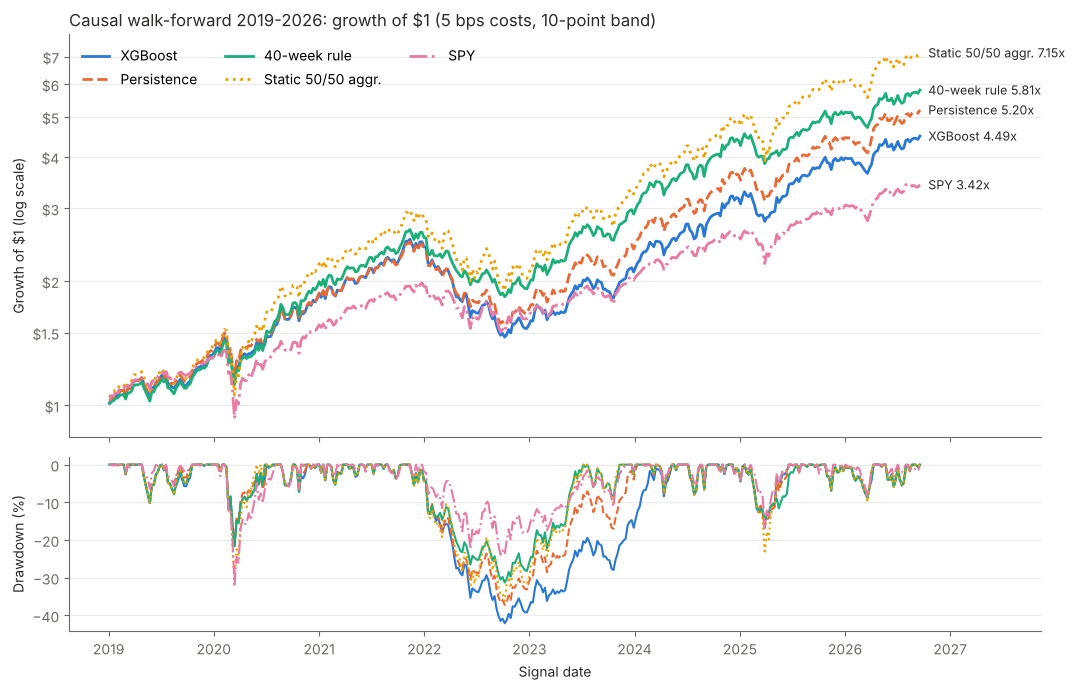

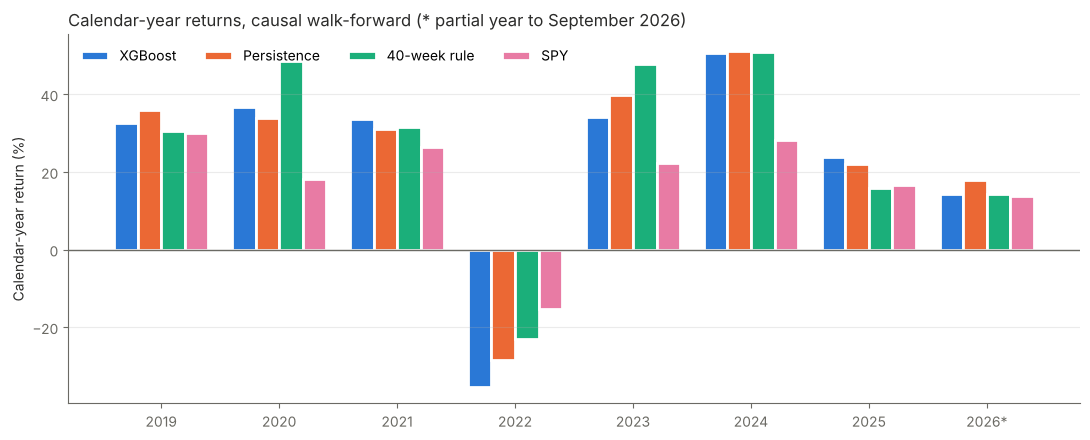

Date                         2019  2020  2021  2022  2023  2024  2025  2026
XGBoost (causal labels)      32.5  36.9  33.5 -35.3  34.3  50.7  24.0  14.3
Persistence (causal labels)  36.0  34.0  31.1 -28.4  39.8  51.1  22.0  17.9
Rule: SPY below 40w MA       30.5  48.7  31.5 -22.9  47.8  50.9  15.8  14.3
SPY buy-and-hold             30.2  18.1  26.3 -15.4  22.4  28.1  16.8  13.8


In [ ]:
#  7.4 Figures for the report: walk-forward growth and drawdown; calendar-year returns 
PAL = {"XGBoost (causal labels)": "#2a78d6", "Persistence (causal labels)": "#eb6834",
       "Rule: SPY below 40w MA": "#1baf7a", "Static 50% SPY + 50% Aggr.": "#eda100", "SPY buy-and-hold": "#e87ba4"}
SHORT = {"XGBoost (causal labels)": "XGBoost", "Persistence (causal labels)": "Persistence",
         "Rule: SPY below 40w MA": "40-week rule", "Static 50% SPY + 50% Aggr.": "Static 50/50 aggr.",
         "SPY buy-and-hold": "SPY"}
STY = {"XGBoost (causal labels)": "-", "Persistence (causal labels)": "--", "Rule: SPY below 40w MA": "-",
       "Static 50% SPY + 50% Aggr.": ":", "SPY buy-and-hold": "-."}
INK, MUTED = "#2b2b2a", "#6b6a64"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False})

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
for name, col in PAL.items():
    eq = (1 + rets8[name]).cumprod()
    a1.plot(eq.index, eq, color=col, lw=2, ls=STY[name], label=SHORT[name])
    a1.annotate(f"{SHORT[name]} {eq.iloc[-1]:.2f}x", (eq.index[-1], eq.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK)
    dd = eq / eq.cummax() - 1
    a2.plot(dd.index, 100 * dd, color=col, lw=1.5, ls=STY[name])
a1.set_yscale("log"); a1.set_ylabel("Growth of $1 (log scale)")
from matplotlib.ticker import FixedLocator, NullLocator
a1.yaxis.set_major_locator(FixedLocator([1, 1.5, 2, 3, 4, 5, 6, 7])); a1.yaxis.set_minor_locator(NullLocator())
a1.set_yticklabels(["$1", "$1.5", "$2", "$3", "$4", "$5", "$6", "$7"])
a1.set_title("Causal walk-forward 2019-2026: growth of $1 (5 bps costs, 10-point band)", color=INK, loc="left")
a1.legend(loc="upper left", frameon=False, ncol=3); a1.grid(axis="y", alpha=0.25)
a2.set_ylabel("Drawdown (%)"); a2.set_xlabel("Signal date"); a2.grid(axis="y", alpha=0.25)
a1.set_xlim(right=wc[-1] + pd.Timedelta(days=420))
plt.tight_layout(); plt.savefig("results/figures/walkforward_growth_drawdown.png", dpi=120); plt.show()

yr8 = pd.DataFrame({k: rets8[k] for k in ["XGBoost (causal labels)", "Persistence (causal labels)",
                                          "Rule: SPY below 40w MA", "SPY buy-and-hold"]})
yr8 = yr8.groupby(yr8.index.year).apply(lambda x: (1 + x).prod() - 1) * 100
fig, ax = plt.subplots(figsize=(11, 4.5))
w_, n_ = 0.2, yr8.shape[1]
for j, name in enumerate(yr8.columns):
    ax.bar(np.arange(len(yr8)) + (j - (n_ - 1) / 2) * w_, yr8[name], width=w_, color=PAL[name],
           edgecolor="white", linewidth=2, label=SHORT[name])
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(np.arange(len(yr8))); ax.set_xticklabels([f"{y}*" if y == yr8.index.max() else str(y) for y in yr8.index])
ax.set_ylabel("Calendar-year return (%)"); ax.grid(axis="y", alpha=0.25); ax.legend(frameon=False, ncol=4, loc="upper left")
ax.set_title("Calendar-year returns, causal walk-forward (* partial year to September 2026)", color=INK, loc="left")
plt.tight_layout(); plt.savefig("results/figures/walkforward_calendar_years.png", dpi=120); plt.show()
print(yr8.round(1).T.to_string())